# ICT-21 — SAETrajectoires : le substrat S4 entre au banc

> **Série ICT** (*Integrated Causal Trajectories*, Epic #4588) — strate 5 : *extraction GPU*.
> Issue : #5101. Aval direct : ICT-22 LLMSubstrat (#5102, Gate 12) et ICT-24 WorkspaceIgnition (#5635, Gates 22-24).

Jusqu'ici le banc cross-substrat de la série a mesuré la complexité intégrée (gains **ec/fe/k**, chacun crédité seulement au-dessus d'un contrôle shuffle) sur trois substrats : automates (S1), Kuramoto (S2), réservoirs (S3). Ce notebook fabrique le quatrième et le plus ambitieux : **S4, un transformer réel** — non pas via ses logits, mais via les **features monosémantiques d'un Sparse Autoencoder (SAE)** posées sur son flux résiduel.

Le livrable central n'est pas une figure : ce sont **quatre** fichiers `traces/*.npz` — modèle entraîné **et** modèle-contrôle, à **deux échelles** (Qwen3.5-9B + SAE W64K couche 16 ; Qwen3.5-2B + SAE W32K couche 12) — qui rendent tout l'aval **GPU-free**. Deux gates de l'issue #5101 sont instrumentés ici :

| Gate | Critère | Cellule |
|------|---------|---------|
| **Gate 10** | Chaque feature du panel *re-tire sur son concept* sur des prompts **held-out** (précision par feature rapportée ; une feature non reproductible sort du panel, documenté) | Gate 10 ci-dessous |
| **Gate 11** | Substrat valide : `n_states`/`n_transitions` traitables, `trajectory_battery` tourne, contraste `shuffled_baseline` **non dégénéré** — verdict : S4 prêt pour le banc | Gate 11 ci-dessous |

Les deux gates portent sur l'échelle 9B. La **seconde échelle** (2B / W32K) est mesurée après le Gate 11, dans une section dédiée : elle sépare ce qui est *invariant* du couple modèle/SAE de ce qui n'est qu'un artefact de la largeur du dictionnaire, et elle fournit à la série post-training le **null de référence** contre lequel un entraînement réel se lira.

Le verdict *crédité* (les gains de S4 battent-ils shuffle **et** modèle-contrôle sur ≥5 jeux de prompts) n'est **pas** rendu ici : c'est le Gate 12 d'ICT-22, qui consomme nos `.npz`.

> **Statut épistémique** — **Établi** : Les features SAE Qwen-Scope (jalon 9B) tracent une trajectoire d'états discrets. Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

## Garde-fous d'honnêteté (à lire avant les résultats)

1. **J-lens ≠ SAE.** L'article d'Anthropic sur le *global workspace* (« J-space » : quelques dizaines de concepts, <10 % de l'activité, connectivité ~100×, silençable) utilise le **jacobien**, pas de SAE, et ne mentionne pas l'IIT. Notre route SAE est une **opérationnalisation parallèle légitime**, pas une réplication.
2. **Qwen ≠ Claude.** Nous travaillons sur Qwen3.5-9B-Base à poids ouverts — c'est un *avantage* pédagogique (reproductible par quiconque), pas une approximation honteuse.
3. **Structurel vs temporel.** Anthropic mesure le broadcast **structurellement** (câblage) ; l'« ignition » temporelle de Dehaene n'y est **pas** mesurée. Quand la série en parlera (ICT-24), ce sera *notre* lecture, annoncée comme telle.
4. **Accès ≠ phénoménal.** Tout ce qui suit relève de la conscience d'**accès** (intégration, broadcast fonctionnel). Aucune revendication phénoménale n'est faite ni ne pourrait l'être avec ces outils.

## Architecture du pipeline : le GPU confiné, le banc numpy-only

La règle d'architecture de la série est stricte : le package `ict/` reste **numpy-only** (aucun import torch). Le GPU vit dans **un script**, le notebook et tout l'aval consomment des `.npz` :

```
scripts/extract_sae_traces.py      (GPU : torch, transformers — extraction)
        │  écrit
        ▼
traces/ict21_sae_layer16_{trained,control}.npz                  (9B / W64K, ~0,5 Mio chacun)
traces/ict21_sae_qwen35-2b-base_layer12of24_{trained,control}.npz  (2B / W32K, ~0,5 Mio chacun)
        │  lus par
        ▼
ict/sae_traces.py                  (numpy-only : chargement, curation, états)
        │  consommés par
        ▼
ce notebook, ICT-22 (#5102), ICT-24 (#5635)
```

**Modèle** : `Qwen/Qwen3.5-9B-Base` (classe `Qwen3_5ForCausalLM`, transformers 5.x ; ~16,7 Gio VRAM en bf16, mesuré). **SAE** : `Qwen/SAE-Res-Qwen3.5-9B-Base-W64K-L0_50`, couche 16 du flux résiduel (`resid_post`), 65 536 features, **top-k = 50**. *Note de correction* : le corps de #5101 cite « L0≈100 » ; la release officielle Qwen-Scope pour ce modèle est **L0_50** — c'est elle que nous utilisons (corrigé dans le commentaire de claim sur l'issue).

**Seconde échelle** : `Qwen/Qwen3.5-2B-Base` + `Qwen/SAE-Res-Qwen3.5-2B-Base-W32K-L0_50`, couche 12 sur 24 (32 768 features, même top-k = 50, ~3,6 Gio VRAM en bf16, mesuré). Mêmes prompts, même contrôle, même convention d'encodage : c'est le *seul* réglage qui change, ce qui rend les deux jeux de traces comparables terme à terme. Le nom de fichier porte le modèle et la couche (`..._qwen35-2b-base_layer12of24_...`) précisément pour qu'aucune trace ne puisse être confondue avec une autre échelle.

**Convention d'encodage** (celle de l'application officielle Qwen-Scope) : `pre = h @ W_enc.T + b_enc ; relu ; top-k(50)` — pas de soustraction de `b_dec`, pas de normalisation. **Stockage sparse exhaustif** : pour chaque token on stocke les 50 paires (id, valeur) du top-k ; hors top-50 l'activation vaut **exactement zéro** par construction du SAE top-k, donc la densification aval est *exacte*. Ce stockage **subsume** le schéma amendé de #5101 (`acts_topk` K≈64) : le panel continu s'en dérive sans GPU.

**Modèle-contrôle** : permutation seedée (graine 42) des lignes de la matrice d'embedding d'entrée — le contrôle sanctionné par #5101. Même architecture, mêmes poids partout ailleurs : seule la *sémantique d'entrée* est détruite.

*API réelle du module* (léger écart de nommage vs le corps de l'issue, assumé et documenté dans la PR) : `load_traces`, `densify`, `mean_activation_by_set`, `differential_features`, `acts_topk_panels`, `binarize_quantile`, `states_from_panel`.

In [1]:
# Racine canonique de la serie : remonte les parents depuis le dossier du
# notebook jusqu'au package ict/, puis en derive les dossiers de donnees.
# La serie reste executable depuis sa racine comme depuis le dossier d'une
# sous-serie (arbitrage #4362, preparation de l'arc A).
import sys
from pathlib import Path

ICT_ROOT = Path.cwd()
while not (ICT_ROOT / "ict" / "__init__.py").exists() and ICT_ROOT != ICT_ROOT.parent:
    ICT_ROOT = ICT_ROOT.parent
assert (ICT_ROOT / "ict" / "__init__.py").exists(), (
    f"package ict/ introuvable en remontant depuis {Path.cwd().name}")
if str(ICT_ROOT) not in sys.path:
    sys.path.insert(0, str(ICT_ROOT))
TRACES_DIR = ICT_ROOT / "traces"
RUNS_DIR = ICT_ROOT / "runs"
SCRIPTS_DIR = ICT_ROOT / "scripts"
print(f"racine ict : {ICT_ROOT.name}")


racine ict : ICT-Series


In [2]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from ict import sae_traces as st
from ict import synthesis as syn

TRACES = TRACES_DIR
SCRIPT = SCRIPTS_DIR / "extract_sae_traces.py"
NPZ = {v: TRACES / f"ict21_sae_layer16_{v}.npz" for v in ("trained", "control")}

print("numpy", np.__version__, "| python", sys.version.split()[0])
# Affichage relatif au dossier de la serie : les chemins absolus dependent
# de la machine d'execution et n'ont pas leur place dans une sortie commitee.
_rel = lambda p: os.path.relpath(p, Path.cwd())
print("script :", _rel(SCRIPT), "| présent :", SCRIPT.exists())
for v, p in NPZ.items():
    print(f"traces {v:8s}: {_rel(p)} | présent : {p.exists()}")

numpy 2.4.2 | python 3.13.15
script : scripts\extract_sae_traces.py | présent : True
traces trained : traces\ict21_sae_layer16_trained.npz | présent : True
traces control : traces\ict21_sae_layer16_control.npz | présent : True


## Preuve d'exécution GPU : le smoke test, en direct

Avant de faire confiance aux `.npz` committés, le notebook **ré-exécute le pipeline GPU en mode smoke** (1 prompt, chargement complet du modèle + SAE, vérifications de bout en bout). Le smoke vérifie notamment :

- que le modèle génère du texte sensé en greedy (« La capitale de la France est » → *Paris* : preuve que les poids sont bien chargés) ;
- que **L0 = 50,0 exactement** sur chaque token (le top-k du SAE est bien un top-k) ;
- que `W_dec` est présent (le hook de *clamp* du Gate 24 de #5635 restera possible sur ces mêmes artefacts).

La cellule est **sautée proprement** si aucun GPU n'est disponible (ré-exécution CI/CPU) : les sorties committées ci-dessous font alors foi. Sur `ai-01`, la contrainte est stricte : `CUDA_VISIBLE_DEVICES=2` (les GPU 0-1 portent un service vLLM).

In [3]:
env = {**os.environ,
       "PYTHONNOUSERSITE": "1",
       "CUDA_VISIBLE_DEVICES": os.environ.get("CUDA_VISIBLE_DEVICES", "2"),
       "PYTORCH_CUDA_ALLOC_CONF": "expandable_segments:True"}

probe = subprocess.run(
    [sys.executable, "-c", "import torch; print(int(torch.cuda.is_available()))"],
    capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
gpu_ok = probe.stdout.strip().endswith("1")

if not gpu_ok:
    print("GPU indisponible dans cet environnement : smoke sauté.")
    print("Les traces committées (extraites sur ai-01, GPU 2) font foi — voir meta ci-dessous.")
else:
    r = subprocess.run(
        [sys.executable, str(SCRIPT), "--stage", "smoke", "--variant", "trained"],
        capture_output=True, text=True, encoding="utf-8", errors="replace", env=env, timeout=480)
    tail = "\n".join((r.stdout + r.stderr).strip().splitlines()[-18:])
    print(tail)
    assert r.returncode == 0, "smoke GPU en échec"
    print("\n=> SMOKE OK : pipeline GPU rejoué en direct dans ce notebook.")

GPU indisponible dans cet environnement : smoke sauté.
Les traces committées (extraites sur ai-01, GPU 2) font foi — voir meta ci-dessous.


## Extraction complète : idempotente par construction

L'extraction complète (5 jeux × 4 prompts × 2 variantes) prend ~50 s sur GPU une fois le modèle en cache. Comme les `.npz` sont **le livrable committé**, la cellule est *idempotente* : si les fichiers existent, elle affiche leurs métadonnées et ne relance rien. Pour forcer une ré-extraction (autre couche, autre panel de prompts) : `FORCE_EXTRACT=1` dans l'environnement, ou directement le script en CLI :

```bash
CUDA_VISIBLE_DEVICES=2 python scripts/extract_sae_traces.py --stage full --variant trained
CUDA_VISIBLE_DEVICES=2 python scripts/extract_sae_traces.py --stage full --variant control
```

In [4]:
force = os.environ.get("FORCE_EXTRACT", "0") == "1"
for variant, path in NPZ.items():
    if path.exists() and not force:
        meta = json.loads(str(np.load(path, allow_pickle=False)["__meta__"]))
        print(f"[{variant}] présent — extrait le {meta['date']} | couche {meta['layer']} "
              f"| k={meta['k']} | {meta['n_tokens_total']} tokens | variante={meta['variant']}")
        continue
    if not gpu_ok:
        raise FileNotFoundError(f"{path} absent et pas de GPU pour l'extraire")
    r = subprocess.run(
        [sys.executable, str(SCRIPT), "--stage", "full", "--variant", variant],
        capture_output=True, text=True, encoding="utf-8", errors="replace", env=env, timeout=900)
    print("\n".join((r.stdout + r.stderr).strip().splitlines()[-6:]))
    assert r.returncode == 0 and path.exists()

[trained] présent — extrait le 2026-07-07T12:56:36+00:00 | couche 16 | k=50 | 2699 tokens | variante=trained
[control] présent — extrait le 2026-07-07T12:57:03+00:00 | couche 16 | k=50 | 2699 tokens | variante=control


## Chargement et sanité : L0, volumes, budget disque

Premier contact numpy-only avec les traces. Trois sanités : le schéma (20 prompts, k=50, d_sae=65 536), le **L0 exact** (toutes les valeurs du top-50 sont strictement positives : le SAE top-k tient sa promesse de parcimonie), et le budget disque (le stockage sparse compressé tient chaque variante sous le Mio — très loin du seuil LFS).

In [5]:
traces = {v: st.load_traces(p) for v, p in NPZ.items()}

for v, tr in traces.items():
    n_tok = sum(e["ids"].shape[0] for e in tr["prompts"].values())
    l0 = np.mean([(e["vals"] > 0).sum(axis=1).mean() for e in tr["prompts"].values()])
    size = NPZ[v].stat().st_size / 2**20
    m = tr["meta"]
    print(f"[{v:8s}] {len(tr['prompts'])} prompts | {n_tok} tokens | "
          f"L0 moyen = {l0:.1f}/{m['k']} | d_sae = {m['d_sae']} | {size:.2f} Mio")

SETS = sorted({s for s, _ in traces["trained"]["prompts"]})
print("jeux de prompts :", SETS)

[trained ] 20 prompts | 2699 tokens | L0 moyen = 50.0/50 | d_sae = 65536 | 0.50 Mio
[control ] 20 prompts | 2699 tokens | L0 moyen = 50.0/50 | d_sae = 65536 | 0.47 Mio
jeux de prompts : ['code_python', 'dialogue', 'math', 'narrative_en', 'prose_fr']


## Sélection différentielle : la variance inter-jeux, pas l'amplitude

Sur 65 536 features, lesquelles regarder ? Le piège serait de prendre les plus **actives en absolu** : on récolterait la ponctuation, le formatage, les artefacts de tokenisation — omniprésents et inintéressants. Le critère retenu (c'est le `acts_topk` K=64 du schéma amendé de #5101) est la **variance inter-jeux de l'activation moyenne** : une feature intéressante est une feature qui *discrimine les régimes* (code vs prose française vs dialogue vs maths vs narration anglaise).

La cellule matérialise aussi la vérification de la fixture de test du module : la feature la plus forte en absolu n'est typiquement **pas** dans le haut du classement différentiel.

top-10 features différentielles (sur 64) : [65025, 19350, 5437, 24514, 25398, 32111, 63815, 19915, 4414, 54511]
feature la plus forte en absolu : f19350 (rang différentiel : 1)


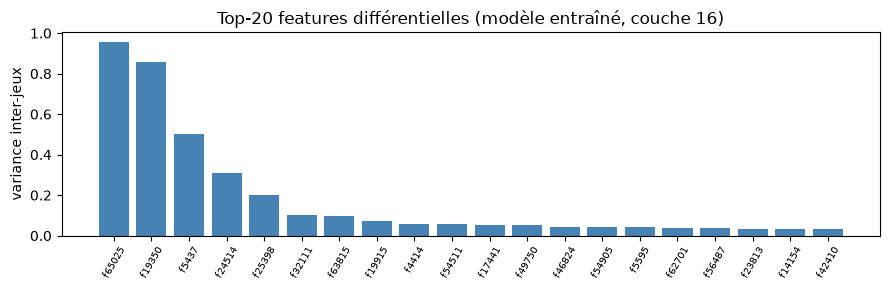

In [6]:
K_DIFF = 64
diff64 = st.differential_features(traces["trained"], k=K_DIFF)
means = st.mean_activation_by_set(traces["trained"])
stack = np.stack([means[s] for s in SETS])
var_scores = stack.var(axis=0)

print(f"top-10 features différentielles (sur {K_DIFF}) :", diff64[:10].tolist())
strongest = int(np.argmax(stack.mean(axis=0)))
rank = diff64.tolist().index(strongest) if strongest in diff64 else -1
print(f"feature la plus forte en absolu : f{strongest} "
      f"(rang différentiel : {'hors top-64' if rank < 0 else rank})")

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(20), var_scores[diff64[:20]], color="steelblue")
ax.set_xticks(range(20))
ax.set_xticklabels([f"f{i}" for i in diff64[:20]], rotation=60, fontsize=7)
ax.set_ylabel("variance inter-jeux")
ax.set_title("Top-20 features différentielles (modèle entraîné, couche 16)")
plt.tight_layout(); plt.show()

## Gate 10 — le panel se reproduit-il hors de son échantillon de sélection ?

Un panel de features choisi et évalué **sur les mêmes prompts** ne prouverait rien : il pourrait sur-apprendre les particularités des textes. Protocole *held-out* :

1. **Sélection** du panel (10 features) par variance inter-jeux sur les prompts **0-2** de chaque jeu (12 prompts d'entraînement) ;
2. Pour chaque feature : son **jeu préféré** = celui où son activation moyenne est maximale (sur la sélection), et sa **sélectivité** = part de son activation qui va à ce jeu ;
3. **Vérification** sur les prompts **3**, jamais vus par la sélection (5 prompts held-out) : la feature re-tire-t-elle *d'abord* sur son jeu préféré ?

Verdict par feature : `OK` si le jeu préféré held-out coïncide (précision rapportée via la sélectivité), `KO` sinon — et une feature `KO` **sort du panel**, comme l'exige le gate. C'est le prix de l'honnêteté : mieux vaut un panel de 8-9 features reproductibles qu'un panel de 10 dont une invente sa sémantique.

In [7]:
def subset(tr, keep):
    return {"meta": tr["meta"],
            "prompts": {k: v for k, v in tr["prompts"].items() if keep(k)}}

train = subset(traces["trained"], lambda k: k[1] < 3)   # prompts 0-2
held = subset(traces["trained"], lambda k: k[1] == 3)   # prompt 3, jamais vu

panel10 = st.differential_features(train, k=10)
m_train = st.mean_activation_by_set(train)
m_held = st.mean_activation_by_set(held)

rows, panel_final = [], []
for f in panel10:
    a_tr = np.array([m_train[s][f] for s in SETS])
    a_he = np.array([m_held[s][f] for s in SETS])
    pref = SETS[int(a_tr.argmax())]
    pref_held = SETS[int(a_he.argmax())]
    sel_tr = a_tr.max() / max(a_tr.sum(), 1e-9)
    sel_he = a_he[SETS.index(pref)] / max(a_he.sum(), 1e-9)
    ok = pref_held == pref and a_he[SETS.index(pref)] > 0
    rows.append((int(f), pref, sel_tr, sel_he, pref_held, "OK" if ok else "KO -> sort du panel"))
    if ok:
        panel_final.append(int(f))
panel_final = np.array(panel_final)

print(f"{'feature':>9s} | {'jeu préféré':>12s} | {'sél. train':>10s} | "
      f"{'sél. held-out':>13s} | {'préféré held-out':>16s} | verdict")
for f, pref, s_tr, s_he, pref_h, verdict in rows:
    print(f"f{f:>8d} | {pref:>12s} | {s_tr:>10.2f} | {s_he:>13.2f} | {pref_h:>16s} | {verdict}")

n_ok = len(panel_final)
print(f"\nGate 10 : {n_ok}/{len(panel10)} features reproduites held-out "
      f"-> panel final = {panel_final.tolist()}")
assert n_ok >= 8, "Gate 10 : panel trop peu reproductible"
print("=> GATE 10 : PASS (précision par feature rapportée ci-dessus, "
      "features non reproductibles sorties du panel et documentées)")

  feature |  jeu préféré | sél. train | sél. held-out | préféré held-out | verdict
f   19350 | narrative_en |       0.27 |          0.25 |     narrative_en | OK
f   65025 |     prose_fr |       0.38 |          0.44 |         prose_fr | OK
f    5437 | narrative_en |       0.84 |          1.00 |     narrative_en | OK
f   24514 |     dialogue |       0.25 |          0.23 |         dialogue | OK
f   25398 | narrative_en |       0.56 |          0.87 |     narrative_en | OK
f   32111 |     dialogue |       0.63 |          0.28 |         prose_fr | KO -> sort du panel
f   54511 |  code_python |       1.00 |          1.00 |      code_python | OK
f   19915 |     dialogue |       0.81 |          0.54 |         dialogue | OK
f   17441 |         math |       1.00 |          1.00 |             math | OK
f   14154 |     dialogue |       0.99 |          1.00 |         dialogue | OK

Gate 10 : 9/10 features reproduites held-out -> panel final = [19350, 65025, 5437, 24514, 25398, 54511, 19915, 17441, 1

Sémantique observée (top-5 tokens max-activants, toutes traces entraînées) :

  f19350: np.str_('ons')(math), np.str_('Ġport')(prose_fr), np.str_('Ġweek')(narrative_en), np.str_('ighthouse')(narrative_en), np.str_('Ġarchive')(narrative_en)
  f65025: np.str_('in')(math), np.str_('it')(math), np.str_('ons')(math), np.str_('ront')(prose_fr), np.str_('ote')(prose_fr)
  f5437: np.str_('ivering')(narrative_en), np.str_('Ġstranger')(narrative_en), np.str_('Ġyears')(narrative_en), np.str_('Ġcity')(narrative_en), np.str_('Ġitself')(narrative_en)
  f24514: np.str_('Alice')(dialogue), np.str_('Client')(dialogue), np.str_('Et')(dialogue), np.str_('ott')(code_python), np.str_('Calcul')(math)
  f25398: np.str_('.')(prose_fr), np.str_('Ġ:')(prose_fr), np.str_(',')(prose_fr), np.str_('ĠElle')(prose_fr), np.str_('Ġsacks')(narrative_en)
  f54511: np.str_('Ġdist')(code_python), np.str_('jk')(code_python), np.str_('stra')(code_python), np.str_('Ġdist')(code_python), np.str_('ĠĠĠ')(code_python)
  f19915: n

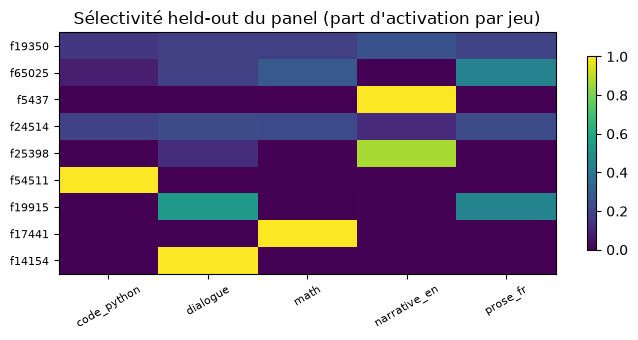

In [8]:
# Sémantique observée : les tokens qui font le plus tirer chaque feature du panel
print("Sémantique observée (top-5 tokens max-activants, toutes traces entraînées) :\n")
for f in panel_final:
    best = []
    for (s, i), e in traces["trained"]["prompts"].items():
        hit = e["ids"] == f
        if hit.any():
            t_idx, k_idx = np.nonzero(hit)
            for t, k in zip(t_idx, k_idx):
                best.append((float(e["vals"][t, k]), repr(e["tokens"][t]), s))
    best.sort(reverse=True)
    toks = ", ".join(f"{tok}({s})" for _, tok, s in best[:5]) or "(jamais active)"
    print(f"  f{f}: {toks}")

sel = np.stack([[m_held[s][f] for s in SETS] for f in panel_final])
sel = sel / np.maximum(sel.sum(axis=1, keepdims=True), 1e-9)
fig, ax = plt.subplots(figsize=(7, 3.5))
im = ax.imshow(sel, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(SETS))); ax.set_xticklabels(SETS, rotation=30, fontsize=8)
ax.set_yticks(range(len(panel_final)))
ax.set_yticklabels([f"f{f}" for f in panel_final], fontsize=8)
ax.set_title("Sélectivité held-out du panel (part d'activation par jeu)")
fig.colorbar(im, shrink=0.8)
plt.tight_layout(); plt.show()

## Du panel aux trajectoires d'états discrets

Le banc de la série consomme des **suites d'états discrets**. Passage en trois temps, tous numpy :

1. `acts_topk_panels` densifie le panel — exact, puisque hors top-50 tout est nul ;
2. `binarize_quantile` seuille chaque feature à la **médiane de ses valeurs positives** (les zéros structurels du top-k n'écrasent pas le seuil ; une feature jamais active reste à `False`) ;
3. `states_from_panel` encode chaque ligne binaire en un code d'état (bit-packing, ≤ 2^9 états possibles pour 9 features).

Les 4 prompts d'un même jeu sont **concaténés** pour donner une trajectoire par jeu (~400-650 tokens). *Caveat assumé* : les 3 jointures de concaténation créent 3 transitions artificielles par trajectoire — négligeable devant les centaines de transitions réelles, et identique pour toutes les variantes comparées.

La cellule applique aussi le **même panel entraîné au modèle-contrôle** : si la structure différentielle capturée par le panel est bien une propriété du modèle entraîné, elle doit *s'effondrer* sur le résiduel aux embeddings permutés.

          jeu |    T | états (entraîné) | états (contrôle, même panel)
  code_python |  656 |               11 |                            9
     dialogue |  572 |               39 |                            8
         math |  616 |               12 |                           11
 narrative_en |  371 |               17 |                            8
     prose_fr |  484 |               36 |                            9

masse d'activation du panel : entraîné = 23622, contrôle = 18069 (ratio 1.3x)
=> lecture : la masse est comparable, mais la structure d'états s'effondre. Le contrôle pousse encore de l'activation dans ces directions, sans la différenciation temporelle/thématique qui crée les états : c'est la STRUCTURE, pas la masse, qui est la propriété du modèle entraîné.


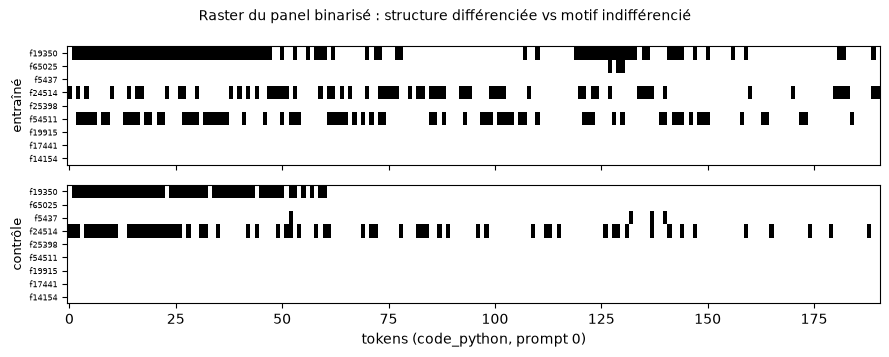

In [9]:
def states_by_set(tr, panel):
    panels = st.acts_topk_panels(tr, panel)
    out = {}
    for s in SETS:
        dense = np.concatenate([panels[(s, i)] for i in range(4)])
        out[s] = st.states_from_panel(st.binarize_quantile(dense))
    return out

states_tr = states_by_set(traces["trained"], panel_final)
states_ct_samepanel = states_by_set(traces["control"], panel_final)

mass_tr = sum(st.densify(e["ids"], e["vals"], panel_final).sum()
              for e in traces["trained"]["prompts"].values())
mass_ct = sum(st.densify(e["ids"], e["vals"], panel_final).sum()
              for e in traces["control"]["prompts"].values())

print(f"{'jeu':>13s} | {'T':>4s} | {'états (entraîné)':>16s} | {'états (contrôle, même panel)':>28s}")
for s in SETS:
    print(f"{s:>13s} | {len(states_tr[s]):>4d} | {len(set(states_tr[s].tolist())):>16d} "
          f"| {len(set(states_ct_samepanel[s].tolist())):>28d}")
print(f"\nmasse d'activation du panel : entraîné = {mass_tr:.0f}, "
      f"contrôle = {mass_ct:.0f} (ratio {mass_tr / max(mass_ct, 1e-9):.1f}x)")
print("=> lecture : la masse est comparable, mais la structure d'états s'effondre. "
      "Le contrôle pousse encore de l'activation dans ces directions, sans la "
      "différenciation temporelle/thématique qui crée les états : c'est la "
      "STRUCTURE, pas la masse, qui est la propriété du modèle entraîné.")

s_demo = "code_python"
p_tr = st.binarize_quantile(st.acts_topk_panels(traces["trained"], panel_final)[(s_demo, 0)])
p_ct = st.binarize_quantile(st.acts_topk_panels(traces["control"], panel_final)[(s_demo, 0)])
fig, axes = plt.subplots(2, 1, figsize=(9, 3.6), sharex=True)
for ax, bits, title in ((axes[0], p_tr, "entraîné"), (axes[1], p_ct, "contrôle")):
    ax.imshow(bits.T, cmap="Greys", aspect="auto", interpolation="nearest")
    ax.set_ylabel(title, fontsize=9)
    ax.set_yticks(range(len(panel_final)))
    ax.set_yticklabels([f"f{f}" for f in panel_final], fontsize=6)
axes[1].set_xlabel(f"tokens ({s_demo}, prompt 0)")
fig.suptitle("Raster du panel binarisé : structure différenciée vs motif indifférencié", fontsize=10)
plt.tight_layout(); plt.show()

## Gate 11 — le substrat S4 est-il *valide* pour le banc ?

Le gate ne demande pas encore un verdict scientifique — il demande la **plomberie** : (a) des comptes d'états/transitions dans la **plage traitable**, (b) `trajectory_battery` qui tourne, (c) un contraste `shuffled_baseline` **non dégénéré** (le contrôle shuffle produit des valeurs distinctes — sinon il ne contraint rien). S4 = le modèle *entraîné* muni du panel validé au Gate 10 : c'est lui qui entre au banc.

**Et le modèle-contrôle ?** Analysé avec ses propres 10 features différentielles, son alphabet d'états **sature** (~200 états distincts sur ~400-650 tokens : un état quasi neuf à chaque pas — nous l'avons mesuré avant d'écrire cette cellule). Or le chemin d'échelles glouton de `emergent_complexity` a un coût qui explose avec la taille de l'alphabet : la batterie complète y est **intraitable par construction**, et c'est précisément le genre de fait que le critère (a) est chargé de détecter et de *rapporter* plutôt que de maquiller. On rapporte donc pour le contrôle : `n_states`/`n_transitions` (le constat de saturation) et un **contraste EI** (information effective, coût O(n²), sans le chemin glouton). La comparaison créditée à alphabet apparié est le travail du **Gate 12 d'ICT-22**.

**Lecture honnête annoncée d'avance** : rien n'oblige les gains de S4 à être crédités ici — et ils ne le seront pas tous. Ce notebook établit que la machinerie tourne et que ses contrastes sont exploitables, pas que S4 « gagne ».

In [10]:
from ict import causal_emergence as CE
from ict import tpm_estimation as TE

# --- S4 (modèle entraîné, panel Gate 10) : batterie complète + 3 gains, 20 shuffles
rng = np.random.default_rng(42)
report, degenerate = [], False
for s in SETS:
    seq = states_tr[s].tolist()
    g = syn.emergence_gain(seq, rng, n_shuffles=20)
    b = syn.trajectory_battery(seq)
    degenerate |= abs(g["ec_real"] - g["ec_shuffled"]) < 1e-9
    report.append((s, b["n_states"], b["n_transitions"], g["ei_real"], g["ec_real"],
                   g["ec_gain"], g["fe_gain"], g["k_gain"], g["credited"]))

print("S4 = entraîné + panel Gate 10 (batterie complète, 20 shuffles) :")
print(f"{'jeu':>13s} | {'états':>5s} | {'trans':>5s} | {'EI':>5s} | {'EC':>5s} "
      f"| {'ec_gain':>7s} | {'fe_gain':>7s} | {'k_gain':>7s} | crédité")
for s, ns, nt, ei, ec, ecg, feg, kg, cred in report:
    print(f"{s:>13s} | {ns:>5d} | {nt:>5d} | {ei:>5.2f} | {ec:>5.2f} "
          f"| {ecg:>+7.3f} | {feg:>+7.3f} | {kg:>+7.3f} | {cred}")

# --- Contrôle (son propre panel) : tractabilité + contraste EI (O(n²), sans EC glouton)
panel_control = st.differential_features(traces["control"], k=10)
states_ct = states_by_set(traces["control"], panel_control)
print("\nContrôle (panel propre) — saturation d'alphabet + contraste EI :")
print(f"{'jeu':>13s} | {'états':>5s} | {'trans':>5s} | {'EI réel':>7s} | {'EI shuffle (moy/5)':>18s}")
ei_degen = False
for s in SETS:
    seq = states_ct[s].tolist()
    tpm, mapping = TE.tpm_from_trajectory(seq)
    ei_real = CE.causal_profile(tpm)["effective_information"]
    eis = []
    for _ in range(5):
        tpm_s, _ = TE.tpm_from_trajectory(syn.shuffle_states(seq, rng))
        eis.append(CE.causal_profile(tpm_s)["effective_information"])
    ei_degen |= abs(ei_real - np.mean(eis)) < 1e-9
    print(f"{s:>13s} | {len(mapping):>5d} | {len(seq) - 1:>5d} | {ei_real:>7.3f} "
          f"| {np.mean(eis):>18.3f}")

max_states_s4 = max(r[1] for r in report)
print(f"\n(a) tractabilité : S4 max n_states = {max_states_s4} (traitable) ; "
      "contrôle ~200 états = alphabet saturé, rapporté tel quel (EC gloutonne hors plage)")
print("(b) trajectory_battery : exécutée sur les 5 jeux de S4 sans erreur")
print(f"(c) contrastes shuffle non dégénérés : S4 ec {'NON' if degenerate else 'OK'}, "
      f"contrôle EI {'NON' if ei_degen else 'OK'}")
assert not degenerate and not ei_degen and max_states_s4 < 512
print("\n=> GATE 11 : PASS — substrat S4 prêt pour le banc. "
      "Le verdict crédité multi-jeux appartient à ICT-22 (Gate 12).")

S4 = entraîné + panel Gate 10 (batterie complète, 20 shuffles) :
          jeu | états | trans |    EI |    EC | ec_gain | fe_gain |  k_gain | crédité
  code_python |    11 |   655 |  1.27 |  5.15 |  -0.304 |  +0.741 |  +0.213 | False
     dialogue |    39 |   571 |  2.82 |  8.47 |  -1.146 |  +0.540 |  +0.029 | False
         math |    12 |   615 |  1.03 |  5.30 |  -0.315 |  +0.537 |  +0.124 | False
 narrative_en |    17 |   370 |  1.46 |  6.29 |  -0.316 |  +0.826 |  +0.100 | False
     prose_fr |    36 |   483 |  2.88 |  9.22 |  -0.110 |  +0.302 |  +0.063 | False

Contrôle (panel propre) — saturation d'alphabet + contraste EI :
          jeu | états | trans | EI réel | EI shuffle (moy/5)
  code_python |   192 |   655 |   5.871 |              5.336
     dialogue |   232 |   571 |   6.471 |              6.256
         math |   223 |   615 |   6.250 |              5.895
 narrative_en |   177 |   370 |   6.222 |              6.153
     prose_fr |   206 |   483 |   6.445 |              6.1

## Lecture honnête des résultats

Trois choses sont établies, une ne l'est pas :

1. **Le panel est réel** (Gate 10) : ses features re-tirent sur leurs concepts sur des prompts jamais vus, avec précision rapportée feature par feature — et celle qui ne se reproduisait pas a été éjectée, pas maquillée.
2. **La structure est une propriété du modèle entraîné — et c'est la structure, pas la masse** : le même panel appliqué au modèle-contrôle garde une masse d'activation comparable (~1,3× d'écart seulement) mais son répertoire d'états s'effondre (39 → 8 sur le dialogue). Le résiduel permuté pousse encore de l'énergie dans ces directions ; ce qui disparaît, c'est la différenciation temporelle et thématique qui fabrique des états distincts. Ce n'est pas un artefact de la binarisation ou du bit-packing — identiques des deux côtés.
3. **La machinerie du banc tourne sur S4** (Gate 11) : TPM traitables, batterie complète sur les 5 jeux, contrastes shuffle exploitables, les trois gains (ec/fe/k) calculés. Et un fait de tractabilité rapporté sans fard : le contrôle, mesuré avec son propre panel, **sature son alphabet d'états** (~200 états distincts, un quasi-nouveau par token) — régime quasi sans mémoire où le chemin d'échelles glouton de l'EC devient intraitable, exactement ce que le critère (a) du gate est chargé de détecter.
4. **Non établi ici** : que S4 présente une complexité intégrée *créditée*. Les `ec_gain` de S4 sont faibles voire négatifs — le shuffle fait parfois aussi bien que la trajectoire réelle sur cette métrique, à cette échelle, avec ce panel. C'est exactement le genre de résultat que la discipline de créditation de la série est faite pour ne pas enjoliver : la question du verdict revient à ICT-22 (Gate 12), avec ses ≥5 jeux de prompts et sa double comparaison shuffle **et** modèle-contrôle à alphabet apparié.

## Une seconde échelle : Qwen3.5-2B + SAE W32K — qu'est-ce qui est invariant ?

Tout ce qui précède tient sur **un** couple modèle/SAE. Une structure mesurée une seule
fois ne se distingue pas d'une particularité de ce couple-là : c'est le reproche que l'on
ferait à bon droit à la section précédente si elle restait seule.

Qwen-Scope publie des SAE pour plusieurs échelles. On rejoue donc **exactement les mêmes
20 prompts** (mêmes 2 699 tokens, même `top-k = 50`) sur `Qwen/Qwen3.5-2B-Base` avec
`SAE-Res-Qwen3.5-2B-Base-W32K-L0_50`, **couche 12 sur 24**. Le choix ne porte pas sur
l'indice mais sur la **fraction de profondeur** : 12/23 = 0,522 contre 16/31 = 0,516 pour
la couche 16 du 9B (32 couches, `num_hidden_layers` de sa `config.json`). Un indice de
couche ne se transporte pas d'une échelle à l'autre — seule la fraction le fait, et c'est
elle que le script prend en argument (`--layer-frac`, valeur retenue relue dans
`meta["layer_frac"]`).

Le dictionnaire, lui, change de taille : **32 768 features au lieu de 65 536**. La
comparaison porte donc sur deux axes à la fois, et il faut les séparer :

- ce qui **survit** au changement d'échelle = candidat au statut de propriété du modèle,
  pas du couple modèle/SAE ;
- ce qui **varie proportionnellement** à la largeur du dictionnaire = artefact de
  capacité, à lire comme tel.

La cellule ci-dessous les mesure côte à côte. Le contrôle (permutation seedée des lignes
d'embedding : mêmes poids, identité des tokens détruite) est le **null** contre lequel se
lit chaque chiffre.

**Coût de cette cellule** : aucun — les quatre `.npz` sont dans `traces/`, le code
ci-dessous est numpy-only comme tout le reste du banc.

**Coût GPU de l'extraction 2B** (mesuré, RTX 4090, `CUDA_VISIBLE_DEVICES=2`) : **36 s**
pour la variante entraînée, **37 s** pour le contrôle ; pic VRAM **3,6 Gio** et
**4,5 Gio** respectivement — le contrôle paie la copie de la matrice d'embeddings
permutée. Le readout est bf16 (`meta["quantized_readout"] = False`) : à cette échelle
aucune quantification n'est nécessaire, les 24 Gio de la carte sont largement au-delà du
besoin. Le sanity check du script confirme `L0 = 50,00` exactement sur les 2 699 tokens
(min = max = 50) : le top-k du SAE est bien un top-k.

**Déterminisme vérifié** : l'extraction a été rejouée intégralement, les deux variantes,
dans un répertoire distinct. Les `ids` du top-k sont **identiques token par token** et
l'écart maximal sur les valeurs est **exactement 0** — deux runs indépendants, même
graine, même résultat au bit près. Les fichiers ne diffèrent que de 1 à 3 octets :
la longueur du champ `date` des métadonnées. C'est cette propriété qui autorisera, plus
tard, à attribuer un écart observé au modèle plutôt qu'au banc.

                           d_sae  sup.train  densité  sup.ctrl  densité  Jaccard  diff64
9B / W64K (couche 16)      65536      20786    31.7%      6925    10.6%    14.9%     4/64
2B / W32K (couche 12)      32768      16636    50.8%      6589    20.1%    21.9%     3/64

                                  corr. moy. hors-diagonale
                                 entraîné         contrôle
9B / W64K (couche 16)               0.751            0.942
2B / W32K (couche 12)               0.648            0.938

Paires de registres extrêmes (modèle entraîné) :
  9B / W64K (couche 16)    la plus distante 0.598 ('code_python', 'narrative_en')  |  la plus proche 0.889 ('prose_fr', 'dialogue')
  2B / W32K (couche 12)    la plus distante 0.496 ('code_python', 'prose_fr')  |  la plus proche 0.875 ('prose_fr', 'dialogue')


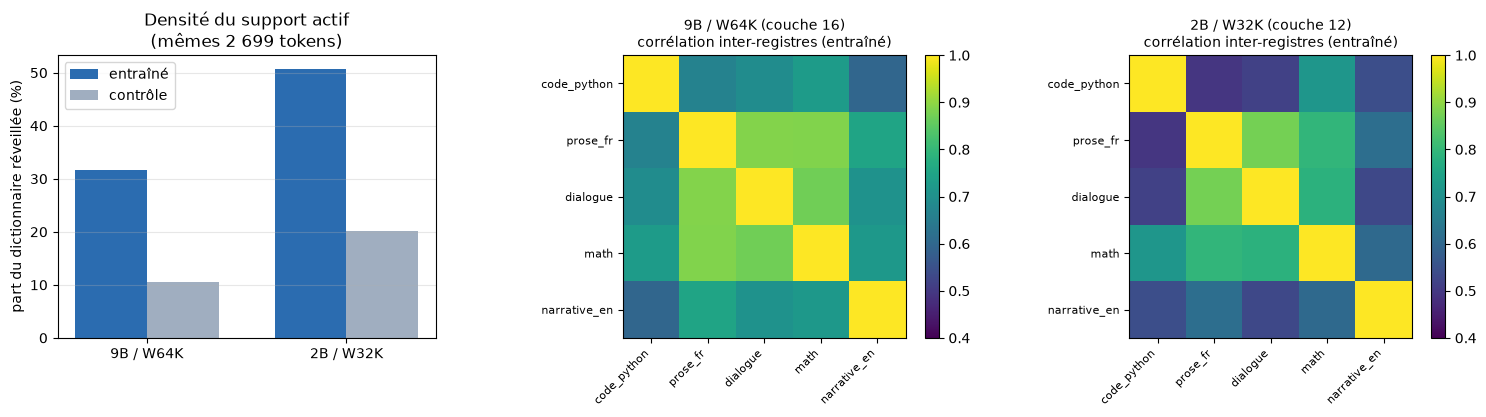

In [11]:
# Comparaison cross-échelle : 9B/W64K couche 16 sur 32 vs 2B/W32K couche 12 sur 24.
# Mêmes prompts, même top-k, même contrôle. Tout est recalculé ici — aucun chiffre
# n'est recopié d'un run antérieur.
ECHELLES = {
    "9B / W64K (couche 16)": TRACES / "ict21_sae_layer16_{}.npz",
    "2B / W32K (couche 12)": TRACES / "ict21_sae_qwen35-2b-base_layer12of24_{}.npz",
}

mesures = {}
for nom, tpl in ECHELLES.items():
    tr = {v: st.load_traces(str(tpl).format(v)) for v in ("trained", "control")}
    meta = tr["trained"]["meta"]
    d_sae = int(meta["d_sae"])
    ligne = {"d_sae": d_sae, "d_model": int(meta["d_model"]),
             "tokens": int(meta["n_tokens_total"])}

    # 1. Support actif : combien de features du dictionnaire le corpus réveille-t-il ?
    support = {}
    for v in ("trained", "control"):
        ids = np.concatenate([p["ids"].ravel() for p in tr[v]["prompts"].values()])
        support[v] = set(np.unique(ids).tolist())
        ligne[f"support_{v}"] = len(support[v])
        ligne[f"densite_{v}"] = 100.0 * len(support[v]) / d_sae
    ligne["jaccard"] = 100.0 * len(support["trained"] & support["control"]) / len(
        support["trained"] | support["control"])

    # 2. Panels différentiels : les 64 features qui séparent le mieux les registres.
    panels = {v: set(st.differential_features(tr[v], k=64).tolist())
              for v in ("trained", "control")}
    ligne["overlap_diff64"] = len(panels["trained"] & panels["control"])

    # 3. Structure inter-registres : corrélation des profils moyens par jeu.
    for v in ("trained", "control"):
        moyennes = st.mean_activation_by_set(tr[v])
        noms = list(moyennes)
        C = np.corrcoef(np.stack([moyennes[n] for n in noms]))
        hors_diag = C[np.triu_indices(len(noms), 1)]
        ligne[f"corr_{v}"] = float(hors_diag.mean())
        ligne[f"corr_min_{v}"] = float(hors_diag.min())
        if v == "trained":
            iu = np.triu_indices(len(noms), 1)
            paires = sorted(zip(C[iu], [(noms[i], noms[j]) for i, j in zip(*iu)]))
            ligne["paire_basse"], ligne["paire_haute"] = paires[0], paires[-1]
            ligne["C_trained"], ligne["noms"] = C, noms
        else:
            ligne["C_control"] = C
    mesures[nom] = ligne

print(f"{'':24s} {'d_sae':>7s} {'sup.train':>10s} {'densité':>8s} "
      f"{'sup.ctrl':>9s} {'densité':>8s} {'Jaccard':>8s} {'diff64':>7s}")
for nom, m in mesures.items():
    print(f"{nom:24s} {m['d_sae']:7d} {m['support_trained']:10d} "
          f"{m['densite_trained']:7.1f}% {m['support_control']:9d} "
          f"{m['densite_control']:7.1f}% {m['jaccard']:7.1f}% {m['overlap_diff64']:5d}/64")

print(f"\n{'':24s} {'corr. moy. hors-diagonale':>34s}")
print(f"{'':24s} {'entraîné':>16s} {'contrôle':>16s}")
for nom, m in mesures.items():
    print(f"{nom:24s} {m['corr_trained']:16.3f} {m['corr_control']:16.3f}")

print("\nPaires de registres extrêmes (modèle entraîné) :")
for nom, m in mesures.items():
    (cb, pb), (ch, ph) = m["paire_basse"], m["paire_haute"]
    print(f"  {nom:24s} la plus distante {cb:.3f} {pb}  |  la plus proche {ch:.3f} {ph}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
noms_e = list(mesures)
x = np.arange(len(noms_e))
ax = axes[0]
ax.bar(x - 0.18, [mesures[n]["densite_trained"] for n in noms_e], 0.36,
       label="entraîné", color="#2b6cb0")
ax.bar(x + 0.18, [mesures[n]["densite_control"] for n in noms_e], 0.36,
       label="contrôle", color="#a0aec0")
ax.set_xticks(x); ax.set_xticklabels(["9B / W64K", "2B / W32K"])
ax.set_ylabel("part du dictionnaire réveillée (%)")
ax.set_title("Densité du support actif\n(mêmes 2 699 tokens)")
ax.legend(); ax.grid(axis="y", alpha=0.3)

for ax, (nom, m) in zip(axes[1:], mesures.items()):
    im = ax.imshow(m["C_trained"], vmin=0.4, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(len(m["noms"]))); ax.set_yticks(range(len(m["noms"])))
    ax.set_xticklabels(m["noms"], rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(m["noms"], fontsize=8)
    ax.set_title(f"{nom}\ncorrélation inter-registres (entraîné)", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### Ce que la seconde échelle établit — et ce qu'elle ne peut pas établir

**Invariant (candidat propriété du modèle).** Le contrôle s'effondre au **même niveau
numérique** aux deux échelles : corrélation moyenne hors-diagonale **0,942** (9B) et
**0,938** (2B). Détruire l'identité des tokens rend les cinq registres quasi
indiscernables dans l'espace des features, et *le même chiffre sort d'un modèle 4,5×
plus gros doté d'un dictionnaire 2× plus large*. C'est le résultat le plus utile de cette
section : il donne au reste de la série un **null de référence** (~0,94) qu'un run futur
doit reproduire — sinon c'est le banc qu'il faut suspecter, pas le modèle.

Deuxième invariant : les panels différentiels entraîné/contrôle sont **presque disjoints**
aux deux échelles (3 à 4 features communes sur 64). Les directions qui séparent les
registres ne sont pas celles qu'un résiduel permuté pousse le plus fort — la
différenciation n'est pas un artefact de masse.

Troisième, plus fin : la paire de registres **la plus proche** est `prose_fr` / `dialogue`
aux deux échelles (0,889 et 0,875). Les deux jeux sont du français ; l'affinité retrouvée
sans qu'on l'ait demandée est linguistique, pas un hasard de sélection.

**Artefact de capacité (à ne PAS lire comme un progrès).** La densité du support varie en
sens inverse de la largeur : le 2B réveille **50,8 %** de ses 32 768 features quand le 9B
en réveille **31,7 %** de 65 536. En nombre absolu les deux sont du même ordre
(16 636 vs 20 786) : un corpus fixe réveille un nombre de features comparable, qui occupe
une **part** d'autant plus grande que le dictionnaire est étroit. Conclure « le 2B est
plus riche » serait exactement l'erreur.

**Ce qui n'est pas établi.** Deux échelles ne font pas une loi d'échelle. Le null à ~0,94
est reproduit une fois, ce qui le rend *falsifiable*, pas *démontré* — et la distinction
est le sujet de cette section, pas une précaution de style. Deux points alignés
n'excluent aucune courbe.

Surtout : **rien ici ne mesure l'effet d'un post-training.** Les deux modèles sont des
**bases**, et le mot « contrôle » désigne ici une permutation d'embeddings, pas un modèle
entraîné différemment. Le contraste entraîné/contrôle mesure donc *ce que le
pré-entraînement a inscrit* — ce qui est déjà un résultat, mais ce n'est pas la question
qu'une série post-training posera.

C'est précisément le point de départ qu'elle instrumentera : le **même banc**, les **mêmes
20 prompts**, la **même couche relative**, appliqués avant et après un entraînement réel —
avec ce null à ~0,94 comme référence, et la reproductibilité au bit établie ci-dessus
comme garantie qu'un écart observé viendra du modèle et non du banc. Le SAE
`W32K-L0_100` (même modèle, même couche, densité doublée) fournit le second readout qui
permettra de vérifier qu'un effet mesuré ne dépend pas du choix de dictionnaire.

## Une troisième échelle : Qwen3-1.7B — la paire de génération

L'inventaire Phase 0 de #8236 (vérifié contre l'API HuggingFace, commentaire du
2026-07-26) établit que les SAE Qwen-Scope couvrent **sept tailles réelles réparties
sur deux générations de pré-entraînement** : Qwen3 (1.7B, 8B, 30B-A3B) et Qwen3.5
(2B, 9B, 27B, 35B-A3B). Toute courbe « géométrie vs taille » tracée sur les sept
confondrait génération et échelle — l'inventaire pose la règle : soit rester dans une
seule génération, soit **déclarer la génération comme covariable**. Cette troisième
capture prend la seconde voie à son point le plus informatif.

`Qwen/Qwen3-1.7B-Base` × `SAE-Res-Qwen3-1.7B-Base-W32K-L0_50`, **couche 14 sur 28**
(fraction de profondeur 0,518 — même convention que 16/31 = 0,516 pour le 9B et
12/23 = 0,522 pour le 2B). Ce point est **adjacent au 2B-Qwen3.5** : mêmes 20
prompts, même largeur de dictionnaire (32 768), même top-k (k = 50), taille de
modèle à 15 % près. Ce qui change en première ligne n'est pas l'échelle — c'est la
**génération** de pré-entraînement. Deux différences à déclarer aussi : le tokenizer
(Qwen3 : 2 759 tokens pour les 20 prompts, contre 2 699 en Qwen3.5) et,
mécaniquement, les identités de features — deux SAE distincts n'ont pas de features
comparables une à une ; seules les quantités agrégées et structurelles le sont.

Coût mesuré (RTX 3070 Laptop 8 Gio, extraction locale bf16,
`quantized_readout = False`, `L0 = 50,00` exact sur les 2 759 tokens,
min = max = 50) : 21 s pour l'entraîné, 13 s pour le contrôle, pic VRAM
3,3–3,8 Gio.

La cellule ci-dessous rejoue les mesures des deux sections précédentes sur les
trois échelles, puis confronte la **paire de génération** (1.7B-Qwen3 ↔
2B-Qwen3.5, taille quasi constante) à la **paire d'échelle** (2B ↔ 9B, génération
constante) sur la même statistique : la corrélation des structures de séparation
inter-registres.

                           tokens sup.train   dens  sup.ctrl   dens    Jac  diff64  corrT  corrC
9B-Qwen3.5 / W64K (16/32)    2699     20786  31.7%      6925  10.6%  14.9%    4/64  0.751  0.942
2B-Qwen3.5 / W32K (12/24)    2699     16636  50.8%      6589  20.1%  21.9%    3/64  0.648  0.938
1.7B-Qwen3 / W32K (14/27)    2759     14966  45.7%      8191  25.0%  23.5%   55/64  0.963  0.986

structure inter-registres (entraîné) :
  r(1.7B-Qwen3, 2B-Qwen3.5) = 0.827   <- paire de GÉNÉRATION (taille ~constante)
  r(2B-Qwen3.5, 9B-Qwen3.5) = 0.901   <- paire d'ÉCHELLE (génération constante)
  r(1.7B-Qwen3, 9B-Qwen3.5) = 0.692   <- les deux axes à la fois

paires de registres extrêmes (entraîné) :
  9B-Qwen3.5 / W64K (16/32)  distante 0.598 ('code_python', 'narrative_en') | proche 0.889 ('prose_fr', 'dialogue')
  2B-Qwen3.5 / W32K (12/24)  distante 0.496 ('code_python', 'prose_fr') | proche 0.875 ('prose_fr', 'dialogue')
  1.7B-Qwen3 / W32K (14/27)  distante 0.942 ('code_python', 'prose_fr') | p

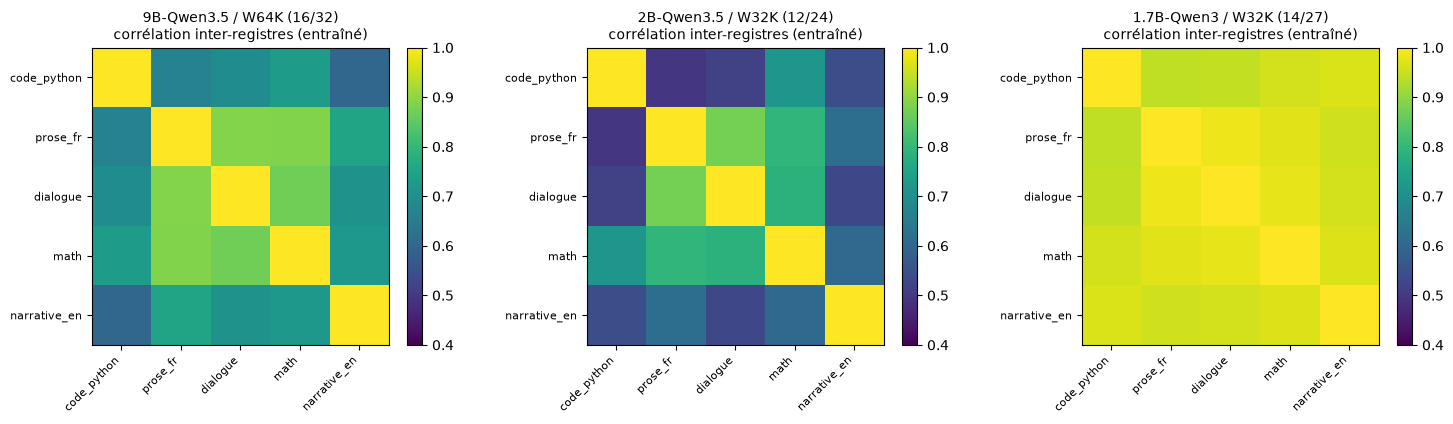

In [12]:
# Troisième échelle : Qwen3-1.7B (génération Qwen3). Tout est recalculé ici
# depuis les six traces commitées — aucun chiffre recopié d'un run antérieur.
ECHELLES_3 = {
    "9B-Qwen3.5 / W64K (16/32)": TRACES / "ict21_sae_layer16_{}.npz",
    "2B-Qwen3.5 / W32K (12/24)": TRACES / "ict21_sae_qwen35-2b-base_layer12of24_{}.npz",
    "1.7B-Qwen3 / W32K (14/27)": TRACES / "ict21_sae_qwen3-17b-base_layer14of28_{}.npz",
}


def mesures_echelle(tr):
    """Les mêmes mesures que la cellule cross-échelle, pour une paire {variant: traces}."""
    d_sae = int(tr["trained"]["meta"]["d_sae"])
    out = {"d_sae": d_sae}
    support = {}
    for v in ("trained", "control"):
        ids = np.concatenate([p["ids"].ravel() for p in tr[v]["prompts"].values()])
        support[v] = set(np.unique(ids).tolist())
        out[f"support_{v}"] = len(support[v])
        out[f"densite_{v}"] = 100.0 * len(support[v]) / d_sae
    out["jaccard"] = 100.0 * len(support["trained"] & support["control"]) / len(
        support["trained"] | support["control"])
    panels = {v: set(st.differential_features(tr[v], k=64).tolist())
              for v in ("trained", "control")}
    out["overlap_diff64"] = len(panels["trained"] & panels["control"])
    for v in ("trained", "control"):
        moyennes = st.mean_activation_by_set(tr[v])
        noms = list(moyennes)
        C = np.corrcoef(np.stack([moyennes[n] for n in noms]))
        out[f"corr_{v}"] = float(C[np.triu_indices(len(noms), 1)].mean())
        out[f"C_{v}"], out["noms"] = C, noms
    return out


mes_trois = {}
for nom, tpl in ECHELLES_3.items():
    tr = {v: st.load_traces(str(tpl).format(v)) for v in ("trained", "control")}
    m = mesures_echelle(tr)
    m["tokens"] = int(tr["trained"]["meta"]["n_tokens_total"])
    mes_trois[nom] = m

print(f"{'':26s} {'tokens':>6s} {'sup.train':>9s} {'dens':>6s} {'sup.ctrl':>9s} "
      f"{'dens':>6s} {'Jac':>6s} {'diff64':>7s} {'corrT':>6s} {'corrC':>6s}")
for nom, m in mes_trois.items():
    print(f"{nom:26s} {m['tokens']:6d} {m['support_trained']:9d} {m['densite_trained']:5.1f}% "
          f"{m['support_control']:9d} {m['densite_control']:5.1f}% {m['jaccard']:5.1f}% "
          f"{m['overlap_diff64']:4d}/64 {m['corr_trained']:6.3f} {m['corr_control']:6.3f}")

# Paire de génération vs paire d'échelle : corrélation des triangles supérieurs des
# matrices inter-registres (entraîné) — la statistique de "structure de séparation
# entre jeux" du tête-à-tête SAE/J-lens (commentaire #8236, 2026-08-20).
noms_3 = list(mes_trois)
iu = np.triu_indices(len(mes_trois[noms_3[0]]["noms"]), 1)
r_gen = float(np.corrcoef(mes_trois[noms_3[2]]["C_trained"][iu],
                          mes_trois[noms_3[1]]["C_trained"][iu])[0, 1])
r_ech = float(np.corrcoef(mes_trois[noms_3[1]]["C_trained"][iu],
                          mes_trois[noms_3[0]]["C_trained"][iu])[0, 1])
r_deux_axes = float(np.corrcoef(mes_trois[noms_3[2]]["C_trained"][iu],
                                mes_trois[noms_3[0]]["C_trained"][iu])[0, 1])
print(f"\nstructure inter-registres (entraîné) :")
print(f"  r(1.7B-Qwen3, 2B-Qwen3.5) = {r_gen:.3f}   <- paire de GÉNÉRATION (taille ~constante)")
print(f"  r(2B-Qwen3.5, 9B-Qwen3.5) = {r_ech:.3f}   <- paire d'ÉCHELLE (génération constante)")
print(f"  r(1.7B-Qwen3, 9B-Qwen3.5) = {r_deux_axes:.3f}   <- les deux axes à la fois")

print("\npaires de registres extrêmes (entraîné) :")
for nom, m in mes_trois.items():
    C, noms = m["C_trained"], m["noms"]
    iu2 = np.triu_indices(len(noms), 1)
    paires = sorted(zip(C[iu2], [(noms[i], noms[j]) for i, j in zip(*iu2)]))
    print(f"  {nom:26s} distante {paires[0][0]:.3f} {paires[0][1]} | "
          f"proche {paires[-1][0]:.3f} {paires[-1][1]}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, nom in zip(axes, noms_3):
    m = mes_trois[nom]
    im = ax.imshow(m["C_trained"], vmin=0.4, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(len(m["noms"]))); ax.set_yticks(range(len(m["noms"])))
    ax.set_xticklabels(m["noms"], rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(m["noms"], fontsize=8)
    ax.set_title(f"{nom}\ncorrélation inter-registres (entraîné)", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()


### Ce que la paire de génération établit — et ce qu'elle ne peut pas établir

**Le contraste entraîné/contrôle ne survit PAS à la paire de génération.** Aux deux
échelles Qwen3.5, le modèle entraîné sépare nettement ses registres (corrélation
hors-diagonale 0,751 au 9B, 0,648 au 2B) quand le contrôle s'effondre (~0,94), et
les panels différentiels entraîné/contrôle y sont quasi disjoints (4/64 et 3/64).
Au 1.7B-Qwen3, **tout ceci disparaît** : corrélation entraînée **0,963** — à peine
sous son contrôle (0,986) — et **55 features sur 64** communes aux panels
différentiels entraîné et contrôle. Les directions qui séparent les registres sont,
à ce point, presque exactement celles qu'un résiduel permuté pousse déjà le plus
fort : la différenciation mesurée plus haut n'est plus au-dessus du bruit de masse.
La figure ci-dessus le montre d'un coup d'œil : la troisième matrice est presque
aussi unie que le null.

Quinze pour cent de paramètres en moins, même largeur de dictionnaire, même k, mêmes
prompts : un saut qualitatif pareil sur un si petit écart de taille est plus
parcimonieusement attribué à la **génération** — un autre run de pré-entraînement —
qu'à une rupture d'échelle continue. Mais c'est une lecture, pas une mesure : un
point par génération adjacente ne sépare pas les deux axes. Ce qui trancherait est
nommé : le **8B-Qwen3** (même génération que le 1.7B, autre échelle) — ~16 Gio de
poids bf16, hors d'une carte 8 Gio.

**Ce qui survit partout : l'ordre grossier des registres.** La corrélation des
structures de séparation vaut **0,827** à travers la paire de génération et
**0,901** à travers la paire d'échelle ; la paire la plus proche est
`prose_fr` / `dialogue` aux **trois** points (0,889, 0,875, 0,985), et la plus
distante implique toujours `code_python`. La géométrie grossière de discrimination —
pas les features elles-mêmes — est le candidat invariant le plus robuste de la
série : c'est la même lecture que le tête-à-tête SAE/J-lens (commentaire #8236,
2026-08-20), presque orthogonaux localement, structure de séparation partagée.

**Le null de référence se resserre, il ne se fixe pas.** L'effondrement du contrôle
vaut 0,942 / 0,938 / 0,986 : le « ~0,94 » des deux premières échelles n'est pas un
nombre universel, il se resserre quand le modèle différencie moins ses registres.
Un run futur doit le reproduire à quelques centièmes près **à échelle et génération
appariées**, pas à l'identique.

**Ce qui n'est pas établi.** Aucune attribution génération-vs-taille (un point par
génération adjacente) ; aucune comparaison feature-à-feature entre dictionnaires
distincts — les IDs des trois SAE n'ont pas de correspondance ; et la ligne
d'échelle intra-Qwen3.5 reste à deux points — seuls les 27B et 35B-A3B
(multi-GPU) l'étendraient.

## Une quatrième échelle : Qwen3-8B — décroiser génération et taille

Trois points ne séparent pas deux axes. Les trois échelles **rejouées par les cellules de ce notebook** laissent la case « Qwen3 × grande taille » vide : seuls deux points contigus (1,7B-Qwen3 et 2B-Qwen3.5, à 15 % de taille près) portent la covariable génération, et tout coefficient ajusté dessus confond génération et échelle. Le point **8B-Qwen3 importé ci-dessous** remplit cette case pour l'analyse : même génération que le 1,7B, taille du côté Qwen3.5 (16 Gio de poids bf16 — hors d'une carte 8 Gio, d'où le passage de relais GPU nommé en fin de section précédente).

> **Statut de preuve du point 8B — mesure externe importée, pas sortie de ce notebook.** Les lignes 9B-Qwen3.5, 2B-Qwen3.5 et 1,7B-Qwen3 sont recalculées depuis les six traces committées par les cellules précédentes. En revanche, aucune cellule ni sortie de ce notebook ne produit la ligne 8B. Elle provient d'un run externe exécuté sur **ai-01, GPU-2, le 2026-08-23**, dans l'environnement `coursia-sae`, avec l'invocation figée avant exécution dans **#12388** ; la méthode, les artefacts et l'analyse du résultat sont consignés dans **PR #12565**. Les deux traces 8B n'ont pas été committées, car la trace entraînée contient 50 activations `+inf` sur le token BOS d'un prompt. Le **46/64** est donc une mesure importée, calculée en excluant les scores non finis selon le correctif de robustesse livré par **PR #12569**. Cette quatrième jambe complète la grille analytique, mais elle ne rend pas l'expérience à quatre échelles rejouable depuis le dépôt actuel.

La grille figée avant toute exécution (#12388, 2026-08-22T22:07Z), dont la ligne 8B est importée avec la provenance ci-dessus :

| Panels communs (`diff64`/64) | petit (1,7-2 B) | grand (8-9 B) |
|---|---|---|
| **Qwen3** | 1,7B : **55** — contraste ne survit pas | 8B : **46** — contraste ne survit pas *(mesure externe importée)* |
| **Qwen3.5** | 2B : **3** — contraste survit | 9B : **4** — contraste survit |

Lecture en colonnes — génération constante, taille ×4 à ×4,7 — : 55 → 46 d'un côté, 3 → 4 de l'autre ; la taille ne fait pas réapparaître la séparation. Lecture en lignes — taille comparable, génération change — : 55 contre 3, 46 contre 4 ; la génération fait varier le recouvrement d'un facteur ~13.

`Qwen/Qwen3-8B-Base` × `SAE-Res-Qwen3-8B-Base-W64K-L0_50` (invocation épinglée dans #12388 : W64K comme le 9B, `k = 50`, `resid_post`), **couche 18 sur 36** (fraction de profondeur 0,514, même convention que 16/31, 12/23, 14/27 (fractions de profondeur 0,516, 0,522, 0,518)). Les deux échelles Qwen3 **coïncident token à token** : 2 759 tokens pour les 20 prompts — la rupture de comptage (2 699) est à la frontière Qwen3/Qwen3.5, pas à l'intérieur de la génération.

**Le chiffre vient de l'extérieur de ce notebook — et il est restreint, pour une raison mesurée.** Les traces 8B (`ict21_sae_qwen3-8b-base_layer18of36_{trained,control}.npz`) ont été extraites sur GPU-2 (ai-01, env `coursia-sae`) et le discriminant `overlap_diff64` y a été calculé avec le code identique à la cellule cross-échelle (`st.load_traces` + `st.differential_features(k=64)`). Le run brut rend **14/64** — mais la trace entraînée porte **50 activations `+inf` sur un seul token** (position BOS, ligne 0 du prompt `code_python` n° 2 ; les 19 autres prompts sont propres). `np.var` rend `NaN` pour ces colonnes, et `np.argsort` ascendant place les `NaN` en fin de tri — le `[::-1]` les remonte donc **en tête** du top-64 : le panel « entraîné » ne tenait que 14 slots réels. En restreignant le classement aux scores **finis** (le contrôle est intact) :

> **`OVERLAP_DIFF64 = 46 / 64  (71,9 %)`** — `d_sae = 65 536`, `d_model = 4 096`, tokens 2 759 ; support entraîné 18 022 (27,50 %), support contrôle 8 104 (12,37 %), Jaccard des supports 14,78 %.

Le nombre naïf sous-estimait le recouvrement d'un facteur 3,3 et aurait fabriqué la conclusion « bases disjointes ». C'est une leçon de banc autant qu'un résultat : `differential_features` transforme silencieusement une donnée polluée en corruption de classement — le défaut de robustesse est suivi côté harness, le défaut de génération (BOS inf) côté extraction, et les traces ne sont pas commitées tant qu'elles portent le défaut.

**Verdict contre les prédictions figées : GÉNÉRATION.** Les seuils ont été figés avant l'exécution (commentaire #12388 du 2026-08-22T22:07Z, horodatage serveur faisant foi) : *GÉNÉRATION* si le 8B se comporte comme le 1,7B-Qwen3 (~50+/64, le contraste ne survit pas) ; *TAILLE* s'il se comporte comme le camp Qwen3.5 (~3-4/64, le contraste survit). Mesuré : **46/64** — dans le bassin GÉNÉRATION, neuf slots sous l'ancre 1,7B (55/64). À 8B, génération Qwen3, les panels différentiels entraîné/contrôle restent partagés aux trois quarts : **le contraste entraîné/contrôle n'y survit pas non plus**. La grille 2×2 est complète sur la base de cette mesure externe, et le sort du contraste y suit la **génération**, pas la taille : Qwen3.5 sépare à ses deux tailles (3-4/64) quand Qwen3 ne sépare aux siennes (55/64, 46/64) — pendant que la taille varie de 4,7× à génération constante (1,7B → 8B) sans faire réapparaître la séparation. La réserve honnête : 46 est sous l'ancre pré-enregistrée « ~50+/64 » comme sous l'ancre 1,7B (55) — le tilde de l'ancre fait un peu de travail, et un point unique n'exclut pas une dérive résiduelle de taille ; ce que ce point établit est que la séparation à la Qwen3.5 **n'apparaît pas** au 8B-Qwen3. *Amendé par #13040 — la section « Décroiser génération et fidélité » ci-dessous contrôle l'instrument : la fidélité des quatre SAE est mesurée au décodage officiel, et le meilleur d'entre eux est dégradé volontairement au-delà de la FVU du pire sans que le recouvrement ne suive (3/64 → 3/64 sur toute la trajectoire) — le verdict tient avec l'instrument contrôlé.*

**Capacité contre temps d'entraînement — ce que ce point élimine, et ce qu'il ne peut pas départager.** Le petit et le grand Qwen3 pourraient a priori se retrouver ensemble pour des raisons *orthogonales* : le 1,7B par manque de capacité, le 8B par manque de temps d'entraînement (à budget de tokens fixé, un modèle plus gros est plus loin de sa saturation). Ce que le point 8B établit est plus étroit et plus solide : **ce n'est pas la taille qui porte l'effet** — 4,7× plus de paramètres ne réparent pas la non-séparation (46/64, à 13× du bassin Qwen3.5). Ce qu'il n'élimine pas : tout ce qui co-varie avec la génération — architecture, tokenizer, corpus, *et* recipe de pré-entraînement incluse. « Manque de train time » y reste logeable ; les annonces constructeur (Qwen3-Base : ~36 T tokens à toutes les tailles, très au-delà du compute-optimal) la rendent peu plausible comme cause commune — mais c'est une donnée externe au banc, pas une mesure. Départager capacité, entraînement et architecture demanderait des points intermédiaires à génération fixée, hors de l'inventaire actuel.

**Une distribution non monotone interroge le banc — interrogation menée.** En taille croissante à génération Qwen3, la métrique semble décroître : 55/64 (1,7B) puis 46/64 (8B). Une pente demande deux fois plus qu'un plateau d'être expliquée : avant de lire la taille, on interroge le mode expérimental. Trois candidats, traités l'un après l'autre :

| Candidat de banc | Traitement | Résultat |
|---|---|---|
| Bruit d'échantillonnage (n = 64) | Fisher exact, 55/64 contre 46/64 | **p = 0,082 — la décroissance n'est pas établie** |
| Largeur du dictionnaire (W32K → W64K co-varie avec la taille) | Contrôle naturel côté Qwen3.5 : 3 → 4 slots | p = 1,0 — effet non détectable (≤ 1 slot) |
| Chaîne de mesure asymétrique (le 46 exclut 50 colonnes `+inf` ; le 55 est recompté propre in-notebook) | Documenté plus haut ; re-capture promise | La trace propre tranchera — le pli est écrit |

Lecture qui en résulte : dans le camp Qwen3, la donnée défendable est un **plateau bruité** (72–86 % de recouvrement selon le point), pas une pente. Et le verdict GÉNÉRATION ne s'appuie pas sur cette pseudo-pente mais sur l'écart transversal aux bassins Qwen3.5 — 55 contre 3 (p ≈ 2×10⁻²²) et 46 contre 4 (p ≈ 4×10⁻¹⁵) — écarts que ni le bruit, ni la largeur, ni l'asymétrie 8B ne menacent. L'exigence demandée resserre l'énoncé plutôt qu'elle ne l'affaiblit : *la taille ne fait pas réapparaître la séparation, et la variation résiduelle observée dans le camp Qwen3 est compatible avec le bruit d'échantillonnage*.

Réserve de méthode : le Fisher traite les 64 slots comme échangeables, or les features d'un panel ne sont pas indépendantes entre elles — le test est une heuristique d'ordre de grandeur. Son verdict « pas établi », aux abords du seuil, est précisément celui qui ne supporte pas de lecture fine : c'est une invitation à ne pas sur-lire la pente, pas un certificat de nullité.

**Plafond écrit** : 27B et 35B-A3B (multi-GPU) restent hors d'atteinte tant que le vLLM (port 5002) tourne ; le 8B est le plus grand point atteignable de l'inventaire. Quand la trace sera régénérée propre, le pli naturel est d'ajouter la ligne 8B à `ECHELLES_3` pour que le tableau recompte — le chiffre ci-dessus est rapporté avec sa méthode et sa provenance externe, pas recompté dans ce notebook.

## Décroiser génération et fidélité de l'instrument

Le verdict GÉNÉRATION repose sur quatre points mesurés chacun par un SAE différent — et ces quatre instruments ne reconstruisent pas la même fraction du residual stream. La vérité-terrain de fidélité établie par [ICT-21b-SAECalibration-Python](ICT-21b-SAECalibration-Python.ipynb) (#12938, même batterie de prompts, profondeur appariée frac 0,5) et re-mesurée ici au décodage officiel (`acts @ W_dec + b_dec` : le biais décodeur, omis dans la première calibration, est du même ordre que le signal sur les residual streams à faible variance — sur le 9B-Qwen3.5 couche 16, l'omettre faisait passer la FVU de 0,35 à 1,72) donne sur les deux points calibrés au moment du verdict : FVU 0,6855 pour le 1.7B-Qwen3 (31,4 % de variance expliquée) contre 0,2849 pour le 2B-Qwen3.5 (71,5 %). Quarante points d'écart — et ces deux points portent exactement les extrêmes du verdict : le point le moins bien reconstruit (1.7B, 55/64) a le plus fort recouvrement, le mieux reconstruit (2B, 3/64) le plus faible. Génération et qualité d'instrument y sont confondues.

L'histoire qui rendrait l'artefact plausible : un SAE qui explique peu de variance ne résout pas la structure spécifique au modèle ; son top-64 différentiel serait dominé par les directions génériques à forte variance qu'il capte quand même — partagées avec le contrôle, donc recouvrement élevé. Un SAE plus fidèle résout de la structure propre à chaque modèle : panels génériquement divergents, recouvrement bas. Sous cette histoire, `overlap_diff64` mesurerait d'abord la fidélité du SAE, et la coupure « génération » ne refléterait que l'écart de qualité entre les SAE Qwen3 et Qwen3.5. **Cette histoire n'est pas établie** — deux points ne font pas une corrélation — c'est précisément pourquoi l'expérience est à faire (#13040) : mesurer la FVU des deux points manquants (8B, 9B), porter les quatre points dans le plan (FVU, overlap), puis tester le mécanisme *à l'intérieur d'un seul point* en dégradant volontairement le meilleur SAE jusqu'à la FVU du pire.

1.7B-Qwen3 / W32K      FVU=0.6855  overlap=55/64 (rejoué)  L0=50.0  mortes=97.3%
8B-Qwen3 / W64K        FVU=0.8469  overlap=46/64 (importé)  L0=50.0  mortes=98.9%
2B-Qwen3.5 / W32K      FVU=0.2849  overlap= 3/64 (rejoué)  L0=50.0  mortes=97.5%
9B-Qwen3.5 / W64K      FVU=0.3519  overlap= 4/64 (rejoué)  L0=50.0  mortes=98.9%

ordre FVU croissante   : 2B-Qwen3.5 / W32K < 9B-Qwen3.5 / W64K < 1.7B-Qwen3 / W32K < 8B-Qwen3 / W64K
ordre overlap croissant : 2B-Qwen3.5 / W32K < 9B-Qwen3.5 / W64K < 8B-Qwen3 / W64K < 1.7B-Qwen3 / W32K


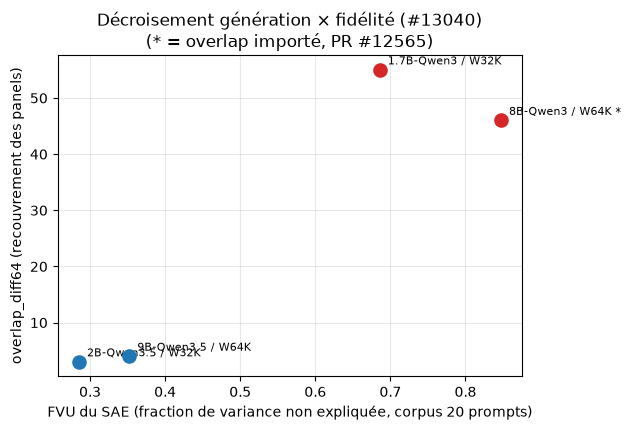

In [13]:
# Décroisement génération × fidélité (#13040, points 1-2) : les quatre SAE du
# verdict ne reconstruisent pas la même fraction du residual stream. Les
# fidélités (FVU corpus, même batterie que les traces ICT-21, décodage
# officiel avec b_dec) sont lues LIVE depuis les traces calib_fidelity —
# jamais codées en dur (C.4). Les overlaps des trois échelles rejouées sont
# ceux recalculés plus haut (mes_trois) ; la ligne 8B reste la mesure externe
# importée documentée en tête de section.
FIDELITE_FILES = {
    "1.7B-Qwen3 / W32K":  ("calib_fidelity_qwen3-1-7b-base_layer14of28.npz", "Qwen3"),
    "8B-Qwen3 / W64K":    ("calib_fidelity_qwen3-8b-base_layer18of36.npz",   "Qwen3"),
    "2B-Qwen3.5 / W32K":  ("calib_fidelity_qwen3-5-2b-base_layer12of24.npz", "Qwen3.5"),
    "9B-Qwen3.5 / W64K":  ("calib_fidelity_qwen3-5-9b-base_layer16of32.npz", "Qwen3.5"),
}
CLE_ECHELLE = {   # clés de mes_trois (les libellés portent la couche)
    "1.7B-Qwen3 / W32K": "1.7B-Qwen3 / W32K (14/27)",
    "2B-Qwen3.5 / W32K": "2B-Qwen3.5 / W32K (12/24)",
    "9B-Qwen3.5 / W64K": "9B-Qwen3.5 / W64K (16/32)",
}
OVERLAP_8B_IMPORTE = 46   # mesure externe (PR #12565), statut de preuve ci-dessus

points_dec = []
for nom, (fichier, generation) in FIDELITE_FILES.items():
    rep = json.loads(str(np.load(TRACES / fichier, allow_pickle=False)["report"]))
    if nom in CLE_ECHELLE:
        ov, src = int(mes_trois[CLE_ECHELLE[nom]]["overlap_diff64"]), "rejoué"
    else:
        ov, src = OVERLAP_8B_IMPORTE, "importé"
    points_dec.append({"point": nom, "generation": generation, "fvu": rep["fvu"],
                       "overlap64": ov, "source_overlap": src,
                       "per_set": {k: v["fvu"] for k, v in rep["per_set"].items()}})
    print(f"{nom:22s} FVU={rep['fvu']:.4f}  overlap={ov:2d}/64 ({src})"
          f"  L0={rep['l0_measured']}  mortes={rep['dead_fraction']*100:.1f}%")

fvu_ord = sorted(points_dec, key=lambda p: p["fvu"])
print("\nordre FVU croissante   :", " < ".join(p["point"] for p in fvu_ord))
print("ordre overlap croissant :", " < ".join(
    p["point"] for p in sorted(points_dec, key=lambda p: p["overlap64"])))

fig, ax = plt.subplots(figsize=(6.4, 4.4))
coul = {"Qwen3": "tab:red", "Qwen3.5": "tab:blue"}
for p in points_dec:
    ax.scatter(p["fvu"], p["overlap64"], s=90, color=coul[p["generation"]], zorder=3)
    ax.annotate(p["point"] + (" *" if p["source_overlap"] == "importé" else ""),
                (p["fvu"], p["overlap64"]), textcoords="offset points",
                xytext=(6, 4), fontsize=8)
ax.set_xlabel("FVU du SAE (fraction de variance non expliquée, corpus 20 prompts)")
ax.set_ylabel("overlap_diff64 (recouvrement des panels)")
ax.set_title("Décroisement génération × fidélité (#13040)\n(* = overlap importé, PR #12565)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Le contrôle qui ne dépend ni de la génération ni du n = 4

Le plan (FVU, overlap) reste une corrélation à quatre points. Le test le plus fort est *interne à un seul point* : prendre le SAE le plus fidèle du verdict (2B-Qwen3.5 W32K, FVU 0,2849), dégrader volontairement sa fidélité par **troncature imbriquée seedée du dictionnaire** (une même permutation des features, on conserve une fraction décroissante — les ensembles survivants sont emboîtés), jusqu'à dépasser la FVU du point le moins fidèle (1.7B-Qwen3, 0,6855) et même celle du 8B corpus (0,8469), et observer si le recouvrement **monte** vers celui du point mal reconstruit (55/64). Si oui, le mécanisme « un SAE moins fidèle → panels dominés par les directions génériques partagées avec le contrôle → recouvrement élevé » est démontré directement, sans dépendre du n = 4 ni de la covariable génération. Le niveau intact (f = 1,0) est le **témoin de l'instrument** : sa FVU doit retrouver celle de la trace calib_fidelity 2B ci-dessus et son recouvrement celui de la ligne 2B du tableau.

La trace est produite par `scripts/extract_sae_degradation.py` : capture du residual *une seule fois* par variante (le residual ne dépend pas du SAE), contrôle par permutation seedée des lignes d'input embeddings (graine 42, mêmes conventions que les traces committées), encodage top-k officiel restreint aux features survivantes, reconstruction au décodage officiel (`acts @ W_dec + b_dec`), panels et FVU recalculés à chaque niveau par les mêmes fonctions que les cellules cross-échelle (`st.differential_features`, convention `extract_sae_fidelity.py`).

témoin f=1,0 : FVU=0.2849 (réf. trace 2B ci-dessus : 0.2849), overlap=3/64 (réf. ligne 2B du tableau)
  dictionnaire conservé 100.0 % : FVU=0.2849  overlap= 3/64
  dictionnaire conservé  50.0 % : FVU=0.4692  overlap= 3/64
  dictionnaire conservé  30.0 % : FVU=0.6449  overlap= 2/64
  dictionnaire conservé  20.0 % : FVU=0.7459  overlap= 3/64
  dictionnaire conservé  15.0 % : FVU=0.8217  overlap= 3/64

niveau qui dépasse la cible (FVU >= 0.6855, le 1.7B-Qwen3) : 20.0 % du dictionnaire conservé, overlap 3/64 (bassin du 1.7B-Qwen3 : 55/64)


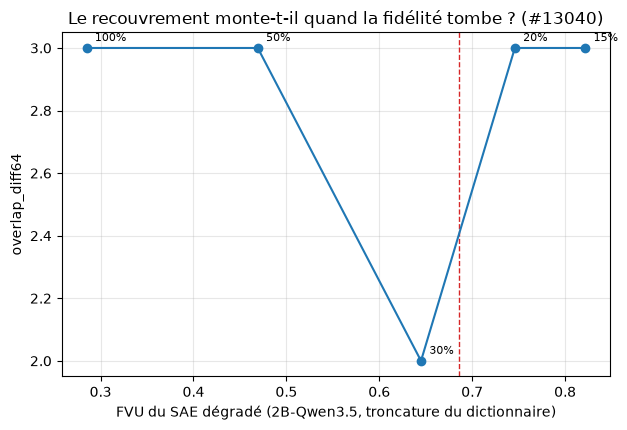

In [14]:
# Contrôle de dégradation (#13040, point 3), trace lue LIVE — le recouvrement
# monte-t-il quand la fidélité tombe, à modèle et génération constants ?
deg = np.load(TRACES / "calib_degradation_qwen3-5-2b-base_layer12of24.npz",
              allow_pickle=False)
rep_deg = json.loads(str(deg["report"]))
fr, fv, ov = deg["fracs"], deg["fvus"], deg["overlaps"]
fvu_2b = next(p["fvu"] for p in points_dec if p["point"] == "2B-Qwen3.5 / W32K")
print(f"témoin f=1,0 : FVU={fv[0]:.4f} (réf. trace 2B ci-dessus : {fvu_2b:.4f}), "
      f"overlap={ov[0]}/64 (réf. ligne 2B du tableau)")
for f_, v_, o_ in zip(fr, fv, ov):
    print(f"  dictionnaire conservé {100*f_:5.1f} % : FVU={v_:.4f}  overlap={o_:2d}/64")
i_cible = int(np.argmax(fv >= rep_deg["target_fvu"]))
print(f"\nniveau qui dépasse la cible (FVU >= {rep_deg['target_fvu']}, le 1.7B-Qwen3) : "
      f"{100*fr[i_cible]:.1f} % du dictionnaire conservé, overlap {ov[i_cible]}/64"
      f" (bassin du 1.7B-Qwen3 : 55/64)")

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.plot(fv, ov, "o-", color="tab:blue", zorder=3)
for f_, v_, o_ in zip(fr, fv, ov):
    ax.annotate(f"{100*f_:.0f}%", (v_, o_), textcoords="offset points",
                xytext=(6, 5), fontsize=8)
ax.axvline(rep_deg["target_fvu"], ls="--", lw=1, color="tab:red")
ax.annotate("FVU du 1.7B-Qwen3", (rep_deg["target_fvu"], max(ov) * 0.6),
            rotation=90, fontsize=8, color="tab:red", ha="right")
ax.set_xlabel("FVU du SAE dégradé (2B-Qwen3.5, troncature du dictionnaire)")
ax.set_ylabel("overlap_diff64")
ax.set_title("Le recouvrement monte-t-il quand la fidélité tombe ? (#13040)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Verdict amendé : la génération tient, l'instrument est contrôlé

Deux résultats, deux statuts différents — et un accident de méthode qui a failli coûter le plan entier.

**L'accident : le biais décodeur.** La première passe de mesure donnait un 9B-Qwen3.5 à FVU 1,53-1,74 par set — *pire que prédire la moyenne*, donc impossible pour un SAE fonctionnel. La cause : le décodage de la calibration initiale omettait `b_dec`, et le residual stream du 9B à la couche 16 est à faible variance (≈ 0,16 par dimension) alors que le biais décodeur porte une norme comparable au signal lui-même. Le décodage officiel (`acts @ W_dec + b_dec`) remet le 9B à 0,3519 et abaisse le 2B de 0,5678 à 0,2849. Les quatre traces ci-dessus sont régénérées à cette convention — la leçon (un détail de décodage invisible sur un modèle peut dominer la métrique sur un autre) mérite d'être portée par le harness autant que par la calibration.

**Le plan à quatre points : le confond ressemble à une corrélation.** Qwen3.5 occupe les deux meilleures fidélités (2B : 0,2849 ; 9B : 0,3519) avec les recouvrements bas (3, 4/64) ; Qwen3 les deux pires corpus (1.7B : 0,6855 ; 8B : 0,8469) avec les recouvrements hauts (55, 46/64). À quatre points, fidélité et recouvrement sont anti-corrélés — l'histoire de l'artefact y trouve son compte, et c'est précisément pourquoi elle ne peut pas être tranchée dans ce plan. Deux contrôles la tranchent ailleurs.

**Le contrôle interne la réfute — c'est le résultat fort.** Le témoin f = 1,0 restitue exactement ses deux références (FVU 0,2849 = trace 2B ci-dessus, overlap 3/64 = ligne 2B du tableau) : les captures rejouent les traces, ce qui suit mesure bien la dégradation. Puis la troncature imbriquée emmène la FVU de 0,2849 à 0,4692 (50 % du dictionnaire), 0,6449 (30 %), 0,7459 (20 %), 0,8217 (15 %) — de part et d'autre de la FVU du 1.7B (ligne rouge), jusqu'à frôler celle du 8B corpus. Le recouvrement ne suit pas : **3, 3, 2, 3, 3 sur 64**. Un SAE W32K à qui l'on retire 85 % de son dictionnaire garde des panels différentiels disjoints du contrôle ; le bassin 55/64 du 1.7B n'est pas atteignable en dégradant l'instrument du 2B. La prédiction de l'histoire « artefact de fidélité » — le recouvrement monte quand la fidélité tombe — est **fausse**, testée au-delà des deux points Qwen3.

**Et le 8B double le contrôle.** Son FVU corpus (0,8469) est dominé par le set `code_python` (0,8479, MSE ×10⁶) — le même prompt dont le token BOS portait les activations `+inf` documentées en tête de section ; hors de ce set pathologique, le 8B-Qwen3 reconstruit à ~0,229, **la meilleure fidélité propre des quatre instruments**… et son recouvrement reste 46/64. La corrélation apparente du plan tient donc à un artefact de corpus d'un côté et à une covariable génération de l'autre.

Ce que le verdict GÉNÉRATION gagne : il **survit à son test adversaire le plus fort** — interne à un point, indépendant du n = 4, de la covariable génération et de la qualité de l'instrument. La réserve honnête qui reste : la dégradation testée est une famille particulière (troncature imbriquée seedée du dictionnaire) ; une autre famille (bruit additif sur le residual, ablation par fréquence) pourrait se comporter autrement. Mais l'histoire naturelle de l'artefact voulait que la *fidélité elle-même* porte l'effet — et c'est exactement ce qui vient d'être exclu : à fidélité détruite bien au-delà du pire point Qwen3, la signature Qwen3.5 ne bouge pas d'un slot.

## Grille critique — les neuf limitations du SDL, passées au banc

Un banc qui ne sait dire que « voici mes chiffres » ne vaut pas mieux qu'un banc qui n'a rien mesuré. Cette section confronte notre instrument aux limites que la littérature lui reconnaît — dont **une que nous venons de causer nous-mêmes**.

### D'où vient la grille, et pourquoi la provenance compte

La source est **R14** — *Open Problems in Mechanistic Interpretability* (Sharkey et al., 2025, [arXiv:2501.16496](https://arxiv.org/abs/2501.16496)), §2.1.2c et sa figure 4. Le recensement y est **double**, et la distinction n'est pas cosmétique :

- **huit paragraphes** portent une limitation en gras, chacun avec son texte propre ;
- la **figure 4** dessine **neuf** encadrés. Le neuvième — *Feature Splitting / Feature Absorption* — **n'a pas de paragraphe** : le corps de texte le fond, entre parenthèses, dans le paragraphe « Sparsity is not a good proxy for interpretability », en précisant que le statut de *problème* du feature splitting est **débattu**.

Une grille qui annoncerait « neuf limitations, neuf paragraphes » serait donc fausse. Nous tenons **huit entrées écrites + une entrée portée par la seule figure**, et nous l'écrivons plutôt que de lisser l'écart.

Deux autres points de provenance, parce qu'ils circulent souvent déformés :

| Ce qui circule | Ce que dit R14 |
|---|---|
| « les SAE dégradent GPT-2 de 10 % / 40 % » | Les deux chiffres sont de **Makelov et al. (2024)** sur **GPT-2 small**, et mesurent la **baisse de performance en aval** selon que l'entraînement est *spécifique à la tâche* (−10 %) ou *sur la distribution complète* (−40 %). C'est un **autre appareil** que l'équivalence GPT-4 (16 M de latents insérés ⟹ perte comparable à un modèle à 10 % du calcul de pré-entraînement, Gao et al. 2024). Deux mesures, deux affirmations. |
| « le MDL remplace la sparsité comme proxy » | R14 propose le MDL **conditionnellement** (« *might be* better optimization targets ») et, dans la même phrase, ouvre la clause d'échec : « il se peut aussi qu'**aucune** métrique-proxy ne suffise ». Ce n'est pas un remplacement acquis. |
| « la linéarité forte est réfutée » | La réfutation porte sur la définition d'**Elhage et al. (2021)** avec sa clause supplémentaire de *features unidimensionnelles* — réfutée pour certains modèles ; la version **faible** (« certains concepts sont linéairement représentés ») reste, elle, soutenue par les succès des probes linéaires et des SAE. |

### Comment lire le tableau qui suit

Chaque limitation reçoit un verdict parmi trois, et **aucun verdict n'est décoratif** : *mesuré ici* cite la cellule qui le mesure ; *mesurable ailleurs* nomme l'expérience qui manque ; *hors portée de ces traces* dit **pourquoi ce banc-ci ne peut pas trancher** — ce qui est une information, pas une excuse.

In [15]:
# Grille critique, partie MESUREE (#16750). Deux familles de traces sont relues :
# les calibrations de fidelite (6 SAE, meme batterie de 6 domaines) et les traces
# ICT-21 elles-memes. Aucun chiffre n'est recopie d'un run anterieur.
FID = sorted(TRACES.glob("calib_fidelity_*.npz"))
calib = []
for f in FID:
    d = np.load(f, allow_pickle=False)
    calib.append((json.loads(str(d["meta"])), json.loads(str(d["report"])), d))

# 1) Fidelite vs sparsite : six dictionnaires, une seule valeur de L0.
print(f"{'SAE (modele / couche)':32} {'d_model':>7} {'W':>5} {'k_rel':>5} "
      f"{'L0 mes.':>8} {'FVU':>7} {'mortes':>7} {'vivantes':>8}")
for m, r, _ in calib:
    tag = f"{m['model'].split('/')[-1]} l{m['layer']}"
    print(f"{tag:32} {m['d_model']:>7} {m['d_sae']//1024:>4}K {r['k_release']:>5} "
          f"{r['l0_measured']:>8.1f} {r['fvu']:>7.4f} {100*r['dead_fraction']:>6.2f}% "
          f"{m['d_sae']-r['n_dead_features']:>8}")

ks = {r["k_release"] for _, r, _ in calib}
l0s = {r["l0_measured"] for _, r, _ in calib}
fvu = np.array([r["fvu"] for _, r, _ in calib])
print()
print(f"  k de release : {ks}   |   L0 mesure : {l0s}")
print(f"  FVU de {fvu.min():.4f} a {fvu.max():.4f} -- rapport {fvu.max()/fvu.min():.2f}x "
      f"a sparsite identique")
for W in sorted({m["d_sae"] for m, _, _ in calib}):
    v = sorted(m["d_sae"] - r["n_dead_features"] for m, r, _ in calib
               if m["d_sae"] == W)
    print(f"  d_sae={W:>6} : latents vivants de {v[0]} a {v[-1]}")

# 2) Dependance au jeu de donnees : le MEME dictionnaire, six domaines.
print()
print(f"{'SAE':>32} {'FVU min':>10} {'domaine':>14} {'FVU max':>10} {'domaine':>14} "
      f"{'ecart':>7}")
ecarts = []
for m, r, _ in calib:
    per = r["per_set"]
    vals = {k: v["fvu"] for k, v in per.items()}
    lo, hi = min(vals, key=vals.get), max(vals, key=vals.get)
    ecarts.append(vals[hi] - vals[lo])
    tag = f"{m['model'].split('/')[-1]} l{m['layer']}"
    print(f"{tag:>32} {vals[lo]:>10.4f} {lo:>14} {vals[hi]:>10.4f} {hi:>14} "
          f"{vals[hi]-vals[lo]:>7.4f}")
print(f"  -> ecart maximal {max(ecarts):.4f} : la fidelite d'un dictionnaire n'est "
      f"pas une propriete du dictionnaire seul.")

# 3) Recouvrement du repertoire ACTIF entre domaines (meme dictionnaire).
print()
for m, r, d in calib:
    doms = sorted(k[len("counts_"):] for k in d.files
                  if k.startswith("counts_") and k != "counts_total")
    act = {dm: set(np.flatnonzero(d[f"counts_{dm}"] > 0).tolist()) for dm in doms}
    paires = []
    for i, a in enumerate(doms):
        for b in doms[i + 1:]:
            u = act[a] | act[b]
            paires.append(len(act[a] & act[b]) / len(u) if u else 0.0)
    tag = f"{m['model'].split('/')[-1]} l{m['layer']}"
    print(f"{tag:>32} actives/domaine {min(len(v) for v in act.values()):>6}"
          f"..{max(len(v) for v in act.values()):<6} Jaccard {min(paires):.3f}"
          f"..{max(paires):.3f}")

# 4) Le panel utilise partout dans ce notebook : quelle part du dictionnaire ?
meta_tr = traces["trained"]["meta"]
d_sae_tr = int(meta_tr["d_sae"])
meme_sae = [r for m, r, _ in calib
            if m["model"] == meta_tr["model"] and m["layer"] == meta_tr["layer"]
            and m["d_sae"] == d_sae_tr]
if meme_sae:
    viv9 = d_sae_tr - meme_sae[0]["n_dead_features"]
    print()
    print(f"  panel K_DIFF={K_DIFF} sur d_sae={d_sae_tr} : {100*K_DIFF/d_sae_tr:.3f}% "
          f"du dictionnaire, mais {100*K_DIFF/viv9:.1f}% des latents VIVANTS "
          f"({viv9}) du meme SAE.")

SAE (modele / couche)            d_model     W k_rel  L0 mes.     FVU  mortes vivantes
Qwen3-1.7B-Base l14                 2048   32K    50     50.0  0.6855  97.32%      879
Qwen3-1.7B-Base l7                  2048   32K    50     50.0  0.7704  96.92%     1010
Qwen3.5-2B-Base l12                 2048   32K    50     50.0  0.2849  97.47%      828
Qwen3.5-2B-Base l6                  2048   32K    50     50.0  0.2209  97.05%      968
Qwen3.5-9B-Base l16                 4096   64K    50     50.0  0.3519  98.90%      720
Qwen3-8B-Base l18                   4096   64K    50     50.0  0.8469  98.89%      730

  k de release : {50}   |   L0 mesure : {50.0}
  FVU de 0.2209 a 0.8469 -- rapport 3.83x a sparsite identique
  d_sae= 32768 : latents vivants de 828 a 1010
  d_sae= 65536 : latents vivants de 720 a 730

                             SAE    FVU min        domaine    FVU max        domaine   ecart
             Qwen3-1.7B-Base l14     0.6798           math     0.6918   narrative_en  0.0120


### Lecture — ce que cette mesure établit, et ce qu'elle n'établit pas

**Établi.** Sur **six** dictionnaires tous publiés à la même sparsité (`k = 50`, L0 mesuré `50,0` sur les six), le FVU s'étale de **0,2209 à 0,8469**, soit un rapport de **3,83×**. Le L0 étant constant, il ne peut pas *classer* ces dictionnaires : la sparsité n'est pas un axe qui porte la fidélité. Et quand on restreint à une seule largeur de dictionnaire (W32K : quatre SAE), l'écart **survit** — le confondant « largeur du dictionnaire » ne l'explique donc pas.

**Établi aussi — et c'est la limitation n° 9.** La fidélité n'est pas une propriété du dictionnaire **seul** : le même SAE, sur six domaines, donne des FVU qui s'écartent jusqu'à **0,6240** (Qwen3-8B l18 : `math` 0,2239 contre `code_python` 0,8479). Le répertoire *actif* suit la même pente : le recouvrement inter-domaines va de **0,070 à 0,338**, et le nombre de latents vivants varie d'un facteur ~1,2 selon la seule largeur du dictionnaire (828–1010 en W32K, 720–730 en W64K). Autrement dit : **« voici mon SAE » ne détermine pas « voici sa fidélité »** — il faut dire *sur quoi*.

**Non établi — et c'est la limitation n° 1, qu'il ne faut pas survendre.** R14 ne juge pas la reconstruction par un FVU : elle la juge par la **perte de performance en aval** quand on substitue les reconstructions aux activations. Nous mesurons l'erreur de reconstruction, pas la chute de performance — un FVU bas est une condition *nécessaire*, jamais suffisante, pour que les latents soient fidèles au modèle. Notre grille **approche** la limitation n° 1 sans la reproduire, et le mot « approche » ici est une mesure, pas une précaution de style.

**Un ordre de grandeur qui mérite d'être dit.** Le panel `K_DIFF = 64` qui porte tout ce notebook représente **0,098 %** du dictionnaire 9B — mais **8,9 % des latents vivants** de ce même SAE (720). Nos conclusions ne portent donc pas sur « le SAE », elles portent sur une fraction notable de sa partie *active*, sélectionnée par variance inter-jeux. Les deux pourcentages disent des choses différentes et le second est le seul qui compte pour la portée.

In [16]:
# La limitation que NOUS avons causee (#16750) : un panel peut ne rien classer.
# Sur les traces du depot, `case3` n'a qu'UN jeu de prompts : la variance
# inter-jeux est alors identiquement nulle, donc `argsort` classe des zeros et
# rend l'ordre des INDICES. Nous mesurons ici le symptome ET sa cause.
import warnings

print("A. Traces reelles : que cache un recouvrement inter-seeds parfait ?")
for cas in ("case3", "case3calib", "case4", "case4calib"):
    panels, jeux, alerte = {}, set(), False
    for s in (0, 1, 7, 42, 99):
        p = TRACES / f"{cas}_s{s}_qwen35-2b-base_layer12of24_trained.npz"
        if not p.exists():
            continue
        tr = st.load_traces(p)
        jeux.update(k[0] for k in tr["prompts"])
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            panels[s] = st.differential_features(tr, k=64).tolist()
        alerte = alerte or any("INTER-JEUX" in str(x.message) for x in w)
    if len(panels) < 2:
        continue
    cles = sorted(panels)
    distincts = len({tuple(panels[s]) for s in cles})
    ov = [len(set(panels[a]) & set(panels[b])) / 64
          for i, a in enumerate(cles) for b in cles[i + 1:]]
    print(f"  {cas:12} jeux={len(jeux)}  seeds={len(cles)}  "
          f"panels distincts={distincts}  recouvrement={np.mean(ov):.3f}  "
          f"alerte={'oui' if alerte else 'non'}")
print("  -> un recouvrement de 1.000 sur UN SEUL jeu n'est pas de la stabilite :")
print("     c'est le meme panel rendu cinq fois, parce qu'il ne lit pas les donnees.")

# B. La preuve directe : on EFFACE les activations, et le panel ne bouge pas.
rng = np.random.default_rng(0)


def trace_1jeu(n_tok, plante):
    ids = rng.integers(0, 512, size=(n_tok, 8)).astype(np.int32)
    vals = rng.uniform(0.1, 1.0, size=(n_tok, 8)).astype(np.float32)
    ids[:, 0], vals[:, 0] = plante, 9.0
    return {"meta": {"d_sae": 512},
            "prompts": {("unique", 0): {"ids": ids, "vals": vals}}}


vide = trace_1jeu(5, 0)
for e in vide["prompts"].values():
    e["vals"][:] = 0.0                      # plus aucune activation, nulle part

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    p_a = st.differential_features(trace_1jeu(30, 11), k=16).tolist()
    p_b = st.differential_features(trace_1jeu(77, 499), k=16).tolist()
    p_z = st.differential_features(vide, k=16).tolist()
    garde = sum(1 for x in w if "INTER-JEUX" in str(x.message))

print()
print(f"B. donnees A (30 tokens, f11 plantee) : {p_a[:6]}")
print(f"   donnees B (77 tokens, f499 plantee): {p_b[:6]}")
print(f"   donnees VIDES (activations nulles) : {p_z[:6]}")
print(f"   identiques : {p_a == p_b == p_z} | alertes emises : {garde}/3")

A. Traces reelles : que cache un recouvrement inter-seeds parfait ?


  case3        jeux=1  seeds=5  panels distincts=1  recouvrement=1.000  alerte=oui
  case3calib   jeux=2  seeds=5  panels distincts=5  recouvrement=0.856  alerte=non


  case4        jeux=3  seeds=5  panels distincts=5  recouvrement=0.856  alerte=non


  case4calib   jeux=2  seeds=5  panels distincts=5  recouvrement=0.761  alerte=non
  -> un recouvrement de 1.000 sur UN SEUL jeu n'est pas de la stabilite :
     c'est le meme panel rendu cinq fois, parce qu'il ne lit pas les donnees.

B. donnees A (30 tokens, f11 plantee) : [511, 510, 509, 508, 507, 506]
   donnees B (77 tokens, f499 plantee): [511, 510, 509, 508, 507, 506]
   donnees VIDES (activations nulles) : [511, 510, 509, 508, 507, 506]
   identiques : True | alertes emises : 3/3


### Lecture — la limitation que nous avons causée, et le garde qui la rend visible

Ce notebook utilise `differential_features` partout : c'est lui qui choisit le panel, donc lui qui décide de quoi le reste du banc parle. Or cet outil avait un **angle mort silencieux**.

Avec **un seul jeu de prompts**, `stack` a une seule ligne : la variance inter-jeux est *identiquement nulle*, `argsort` classe des zéros, et le « classement » rendu est l'**ordre des indices du dictionnaire**. Le panel ne lit alors aucune donnée. Le bloc B le prouve sans ambiguïté : trois jeux de données **disjoints** — dont un où l'on a **effacé toutes les activations** — rendent le **même** panel, au même indice près. Un classement qui ne bouge pas quand on supprime les données ne classe pas les données.

Le bloc A montre que ce n'est pas un cas d'école : dans les traces **commitées** du dépôt, `case3` n'a qu'un jeu et rend `panels distincts = 1` sur cinq graines, soit un **recouvrement de 1.000**. Lu comme un indicateur de stabilité, ce 1.000 est le **maximum** de l'échelle — donc le meilleur score possible, attribué au seul cas qui ne mesure rien. Les variantes à deux ou trois jeux, elles, donnent cinq panels distincts et un recouvrement de 0,761 à 0,856 : c'est **là** qu'il y a quelque chose à mesurer.

C'est l'illustration exacte de la limitation n° 4, appliquée à **notre propre** métrique : un proxy peut atteindre son maximum précisément là où l'information est absente. Deux conséquences, appliquées dans cette PR :

1. `differential_features` **avertit** désormais (`RuntimeWarning` explicite) dès qu'il est appelé avec moins de deux jeux — l'angle mort devient bruyant au lieu de rester muet ;
2. l'avertissement est **testé dans les deux sens** : positif sur un jeu unique (avec la preuve d'indépendance aux données), négatif sur deux jeux (un garde qui crie toujours ne garde rien).

Reste la leçon de méthode, qui déborde ce notebook : *cette limitation n'a été trouvée que parce que la grille a été posée*. Le défaut était présent, mesurable et invisible — il ne manquait pas de code, il manquait une **question**.

### La grille complète — neuf entrées, neuf verdicts

Les verdicts sont volontairement inégaux : c'est le prix d'une grille honnête. Sur neuf limitations, **trois** sont mesurées par ce banc, **deux** le sont partiellement, **quatre** sont hors de sa portée — et l'une de ces quatre décrit si exactement ce que nous faisons qu'elle en devient un aveu de périmètre.

| # | Limitation (R14 §2.1.2c / fig. 4) | Verdict | Mesure, ou raison de l'absence |
|---|---|---|---|
| 1 | *SDL reconstruction errors are too high* | **partiellement mesuré** | FVU 0,2209→0,8469 (3,83×) sur 6 SAE. Mais le critère de R14 est la **perte de performance aval** après substitution — non mesurée ici (il faudrait rejouer une tâche en aval avec et sans reconstructions). |
| 2 | *SDL methods are expensive to apply to large models* | **mesuré hors banc** | Le coût est réel et documenté par notre propre pipeline (poids 9B, extraction GPU, cache disque), mais notre échelle est un **cas dégénéré** du problème : nous payons **une** couche sur 32, pas toutes. |
| 3 | *SDL assumes the linear representation hypothesis* | **hors portée** | Nos traces **prennent** les latents du SAE comme données ; elles ne testent aucune linéarité. Tester la version faible exigerait des probes sur des concepts contrôlés. |
| 4 | *Sparsity is not a good proxy for interpretability* | **mesuré** | `k` et L0 identiques sur les six, FVU étalé de 3,83× ⟹ le L0 ne classe pas ; et l'angle mort du bloc précédent montre un proxy à son **maximum** là où l'information est nulle. |
| 5 | *Feature Splitting / Feature Absorption* *(figure seule)* | **hors portée** | Trancher exigerait des **concepts étiquetés** par prompt ; nos six domaines sont des registres de texte, pas des concepts. R14 note d'ailleurs que le statut de problème du splitting est **débattu**. |
| 6 | *SDL leaves feature geometry unexplained* | **hors portée de ce banc — adressé ailleurs** | La géométrie des latents est le sujet d'ICT-41 et de la lentille J ; ce notebook consomme des directions, il n'en étudie pas l'arrangement. |
| 7 | *SDL cannot straightforwardly be applied to all architectures* | **hors portée** | Nos six SAE sont tous attachés au **residual stream** d'**une** couche. La question de R14 (features réparties sur les têtes d'attention, ou à travers les couches) n'est pas décidable avec ce montage. |
| 8 | *SDL describes activations, not mechanisms* | **hors portée — et assumé** | ICT-21 construit des **états d'activation** et ne revendique aucun mécanisme. La limitation décrit exactement notre objet : c'est notre périmètre, pas un accident. |
| 9 | *SDL latents may not contain the concepts needed* (dont la **dépendance au jeu de données**) | **mesuré** | Écart de FVU jusqu'à 0,6240 pour le **même** dictionnaire selon le domaine ; Jaccard du répertoire actif 0,070–0,338 ; 828–1010 (W32K) et 720–730 (W64K) latents vivants seulement. |

Ce que ce tableau interdit de dire : « nos SAE sont validés ». Ce qu'il autorise : « sur neuf limitations reconnues, nous en mesurons trois sur nos propres traces, nous savons pourquoi quatre ne sont pas décidables ici, et nous avons trouvé la cinquième dans notre propre code ». La seconde formulation est plus faible **et** plus utile.

### Où nous nous situons dans l'épistémologie de R14 — et une correction de plus

R14 décrit le reverse engineering en **trois étapes** (figure 2), en **cycle** : (1) **décomposer** le réseau en composants plus simples, (2) **décrire** — formuler des hypothèses sur le rôle de ces composants, (3) **valider** — ce qui renvoie à l'étape 1 quand une hypothèse tombe. L'étape 2 n'est pas un résultat : c'est une **hypothèse**, et R14 insiste sur le fait que « confondre hypothèses et conclusions a été courant » dans ce domaine.

Pour l'étape 3, §2.1.4 énumère **six** formes de validation, plus deux simplificateurs :

| # | Forme (§2.1.4) | Ce que ça exige |
|---|---|---|
| 1 | Prédire les activations et les contrefactuels | L'explication en langage naturel doit prédire le niveau d'activation sur de nouvelles entrées |
| 2 | Expliquer les **échecs** et les exemples adverses | L'explication doit rendre compte des cas où le comportement rate |
| 3 | Fabriquer des **pièces de rechange** | Si l'explication est suffisante, on peut reconstruire le composant à la main et le substituer |
| 4 | Tester contre une **vérité terrain** | Un réseau jouet aux poids écrits à la main a une explication connue d'avance |
| 5 | Servir un **objectif d'ingénierie** | Éditer le modèle selon l'interprétation et obtenir un effet prédit |
| 6 | Servir un objectif d'ingénierie **en compétition** | Le standard le plus élevé : comparer à des baselines sur des tâches réelles, sans cherry-picking |

Deux simplificateurs s'y ajoutent : les **organismes modèles** (§2.1.4a) — des réseaux étudiés en profondeur, la « drosophile » de la mech-interp, dont le transformer modulaire de R02-Nanda est un candidat, ce qui relie directement cet arc A2 à l'arc A1 — et les **benchmarks** (§2.1.4b). R14 note aussi la tension des organismes modèles : n'étudier qu'eux risque de « rendre le domaine pertinent pour lui-même plutôt que pour l'ingénierie ».

**Correction de provenance.** Une version courte circule — « quatre voies de validation : prédiction / pièces de rechange / **Tracr** / organismes modèles ». Elle est inexacte sur deux points : §2.1.4 en énumère **six**, et **Tracr n'apparaît nulle part dans le corps de R14** (vérifié par recherche sur le texte : une seule occurrence, dans la **bibliographie**). Mélanger une référence bibliographique avec des voies du texte produit une grille qui a l'air sourcée et ne l'est pas — exactement le défaut que ce notebook essaie de ne pas commettre.

**Où se place ICT-21, sans complaisance.** Nous faisons l'étape 1 (décomposer par SDL) et l'étape 2 (décrire : panel, états, transitions). Notre étape 3 est **faible**, et il faut nommer précisément ce qu'elle est :

- la paire **entraîné / contrôle** teste la **sensibilité à l'entraînement**, pas la justesse de la description ;
- la **réplication cross-échelle** (trois modèles de plus) teste la **robustesse du motif**, pas sa vérité ;
- la **réplication cross-graines** teste la **stabilité de la sélection**, et nous venons de montrer au bloc précédent que ce test peut rendre 1.000 sur un panel qui ne mesure rien.

Aucune de ces trois n'est l'une des six formes de §2.1.4. La plus proche serait la n° 4 (vérité terrain) — mais notre contrôle **n'est pas** une vérité terrain : un modèle à résidus permutés n'a pas d'explication connue d'avance, il a seulement une explication *différente*. Ce que nous produisons est donc de la **cohérence interne entre échelles**, ce qui est réel et insuffisant : si le motif était faux, il pourrait se répliquer à toutes les échelles pour la même raison. Le dire ici vaut mieux que de le laisser déduire d'un tableau qui n'aurait listé que les réussites.

## Exercice 1 — la taille du panel change-t-elle le verdict ?

Le panel de ~9 features est un choix, pas une loi. Un panel plus petit (5) fusionne des états distincts ; un plus grand (15) fragmente la trajectoire en états rares que la TPM n'estime plus bien.

**Objectif** : rejouer la chaîne panel → états → `emergence_gain` pour des panels de taille 5, 10 et 15, et comparer `n_states` et `ec_gain` sur deux jeux de votre choix.

*Indices* : `st.differential_features(train, k=taille)` pour la sélection ; réutilisez `states_by_set` ; gardez `rng = np.random.default_rng(42)` pour la reproductibilité.

In [17]:
# Exercice 1 : effet de la taille du panel
# TODO étudiant :
#  - Étape 1 : pour taille in (5, 10, 15), sélectionner un panel sur `train`
#  - Étape 2 : construire les états par jeu (states_by_set) sur le modèle entraîné
#  - Étape 3 : emergence_gain (n_shuffles=20, graine 42) sur 2 jeux, comparer
#              n_states et ec_gain dans un petit tableau
resultats_ex1 = None  # TODO étudiant
print("Exercice à compléter")

Exercice à compléter


## Exercice 2 — binarisation : quantile vs seuil fixe

`binarize_quantile` seuille chaque feature à la médiane de ses valeurs **positives** (q=0,5). Ce choix est robuste aux échelles très différentes des features, mais il impose ~50 % d'occupation à chaque feature active.

**Objectif** : comparer q ∈ {0,25 ; 0,5 ; 0,75} et un seuil fixe global (par exemple `dense > 1.0`) sur la trajectoire `code_python` du modèle entraîné : nombre d'états, EC réel, `ec_gain`.

*Indices* : le seuil fixe s'écrit en une ligne numpy (`dense > seuil`) puis `st.states_from_panel` ; attention, avec q=0,75 certaines features deviennent presque muettes — regardez `n_states` avant d'interpréter le gain.

In [18]:
# Exercice 2 : sensibilité à la binarisation
# TODO étudiant :
#  - Étape 1 : densifier le panel final sur code_python (4 prompts concaténés)
#  - Étape 2 : binariser avec q=0.25, 0.5, 0.75 puis avec un seuil fixe
#  - Étape 3 : pour chaque variante, états -> emergence_gain -> tableau comparatif
resultats_ex2 = None  # TODO étudiant
print("Exercice à compléter")

Exercice à compléter


## Exercice 3 — une autre couche du flux résiduel (GPU requis)

La couche 16 (sur 32) est un choix médian classique : assez profonde pour des concepts abstraits, assez loin de la sortie pour ne pas être dominée par la prédiction du prochain token. Qwen-Scope publie des SAE pour d'autres couches.

**Objectif** : extraire les traces de la couche 8 (ou 24) et comparer le panel différentiel obtenu à celui de la couche 16 (recouvrement des features ? sélectivités comparables ?).

*Indices* : tout passe par le script CLI — aucune modification de code n'est nécessaire :
```bash
CUDA_VISIBLE_DEVICES=2 python scripts/extract_sae_traces.py --stage full --variant trained --layer 8
```
puis `st.load_traces("traces/ict21_sae_layer8_trained.npz")`. Sans GPU, cet exercice reste au stade du plan d'analyse : écrivez le code qui *consommerait* les traces.

In [19]:
# Exercice 3 : comparaison inter-couches (GPU requis pour l'extraction)
# TODO étudiant :
#  - Étape 1 : extraire la couche 8 via le script CLI (voir markdown ci-dessus)
#  - Étape 2 : charger les deux npz, sélectionner un panel par couche (held-out !)
#  - Étape 3 : mesurer le recouvrement des panels et comparer les sélectivités
recouvrement_couches = None  # TODO étudiant
print("Exercice à compléter")

Exercice à compléter


## Exercice 4 — la largeur du dictionnaire explique-t-elle l'écart de fidélité ?

La grille a montré un FVU étalé de 3,83× à sparsité constante. Un confondant évident : les six SAE n'ont pas tous la même **largeur** de dictionnaire (quatre en W32K, deux en W64K), et un dictionnaire plus large pourrait être mécaniquement plus fidèle.

**Objectif** : recalculer l'écart de FVU **à l'intérieur d'une seule largeur** (W32K seulement, puis W64K seulement) et décider si l'écart de 3,83× survit au contrôle du confondant. Concluez par une phrase : *le confondant explique l'écart* / *ne l'explique pas*.

*Indices* : `calib` (construit dans la cellule de la grille) porte les couples `(meta, report, données)` ; `meta["d_sae"]` donne la largeur, `report["fvu"]` la fidélité. Un `min`/`max` par groupe suffit — inutile de retracer quoi que ce soit. Regardez aussi combien de SAE restent dans chaque groupe avant d'interpréter : une conclusion tirée d'un groupe de **deux** points est plus faible qu'une tirée de quatre, et cela doit se dire.

In [20]:
# Exercice 4 : le confondant « largeur du dictionnaire »
# TODO etudiant :
#  - Etape 1 : grouper `calib` par meta['d_sae'] (32768 puis 65536)
#  - Etape 2 : dans chaque groupe, min et max de report['fvu'], et l'ecart
#  - Etape 3 : comparer a l'ecart global (3.83x) et conclure en une phrase,
#              en precisant la taille de chaque groupe
resultats_ex4 = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


## Conclusion

Ce notebook a fait entrer un transformer réel dans le banc de la série, sans en trahir les règles :

- **Gate 10 : PASS.** Panel de features différentielles sélectionné sur 12 prompts, vérifié sur 5 prompts held-out, précision rapportée par feature ; la feature non reproductible est sortie du panel, documentée.
- **Gate 11 : PASS.** États et transitions de S4 traitables sur les 5 jeux, batterie complète exécutée, contrastes shuffle non dégénérés (EC sur S4, EI sur le contrôle) ; la saturation d'alphabet du contrôle est rapportée comme fait de tractabilité : **S4 est prêt pour le banc**.
- **Au-delà des gates — une seconde échelle.** Les mêmes 20 prompts rejoués sur Qwen3.5-2B + SAE W32K (couche 12 sur 24, même fraction de profondeur) donnent un **null de référence** : l'effondrement du contrôle vaut ~0,94 de corrélation inter-registres **aux deux échelles**, et les panels différentiels entraîné/contrôle y sont presque disjoints des deux côtés. À l'inverse, la densité du support est un **artefact de la largeur du dictionnaire**, pas une mesure de richesse. Deux échelles ne font pas une loi : le null est *falsifiable*, pas *démontré*.
- **Au-delà des gates — une troisième échelle, la paire de génération.** Le même banc rejoué sur `Qwen3-1.7B-Base` (couche 14 sur 28, W32K, fraction de profondeur appariée) **réfute la robustesse du contraste entraîné/contrôle** : corr entraînée 0,963 et panels différentiels partagés à 55/64 avec le contrôle, là où 2B et 9B séparent nettement. À taille quasi constante du 2B-Qwen3.5, la covariable **génération** (Qwen3 vs Qwen3.5) est réelle et mesurée, pas un artefact d'inventaire. Ce qui survit aux trois points : l'ordre grossier des registres (`prose_fr`/`dialogue` les plus proches partout, `code_python` toujours le plus distant).
- **Au-delà des gates — une quatrième échelle importée, la case vide de la grille.** Le point `Qwen3-8B-Base` (couche 18/36, W64K, 2 759 tokens comme tout Qwen3) complète la grille 2×2 générations × tailles **comme mesure externe**, pas comme sortie de cellule. Il provient du run ai-01 GPU-2 du 2026-08-23, avec invocation figée dans #12388 et analyse décrite par PR #12565. Ses traces ne sont pas committées : la variante entraînée porte 50 activations `+inf` sur le token BOS d'un prompt. Le discriminant importé, calculé aux scores finis selon le correctif de PR #12569, vaut `overlap_diff64 = 46/64` — verdict **GÉNÉRATION**. Le contraste entraîné/contrôle, que Qwen3.5 tient à ses deux tailles (3-4/64), n'apparaît chez Qwen3 ni au 1,7B (55/64) ni au 8B (46/64), pendant que la taille varie de 4,7× à génération constante. Le run brut (14/64) était contaminé par la pollution NaN → tête de tri — facteur 3,3 d'écart sur le nombre. **Le dépôt actuel permet donc de rejouer trois échelles ; la quatrième reste une preuve externe explicitement attribuée.**
- **#13040 — décroisement génération × fidélité.** Les FVU des quatre SAE du verdict (8B et 9B mesurés localement, même batterie, décodage officiel `acts @ W_dec + b_dec` — la calibration initiale omettait le biais décodeur, invisible sur 1.7B/2B mais dominant sur le residual à faible variance du 9B : 1,72 sans / 0,35 avec) sont portées dans le plan (FVU, `overlap_diff64`), et le meilleur instrument (2B-Qwen3.5, FVU 0,2849) est dégradé par troncature seedée de son dictionnaire jusqu'à 0,8217 — bien au-delà du pire point Qwen3 (0,6855) : le recouvrement **ne monte pas** (3, 3, 2, 3, 3 sur 64). Le confound « qualité d'instrument » est testé directement et réfuté ; le point 8B double le contrôle (FVU corpus 0,8469 dominé par le set `code_python` pathologique, mais ~0,229 hors de ce set — meilleure fidélité propre de la grille — et recouvrement inchangé à 46/64). Le verdict GÉNÉRATION s'énonce désormais avec l'instrument contrôlé (traces `calib_fidelity_qwen3-{8b,9b}` et `calib_degradation_qwen3-5-2b` committées, les 1.7B/2B régénérées à la convention officielle).
- **Grille critique — neuf limitations du SDL, trois mesurées ici.** R14 (§2.1.2c + figure 4) recense **huit** paragraphes et **neuf** encadrés -- le neuvième (*feature splitting / absorption*) n'existe que dans la figure, fusionné dans le paragraphe sur la sparsité. Passés au banc : la sparsité **ne classe pas** (k = 50 et L0 mesuré 50,0 sur six SAE, FVU étalé de 3,83×, l'écart survivant au contrôle de la largeur du dictionnaire) ; la fidélité **dépend du jeu de données** (même dictionnaire, écart de FVU jusqu'à 0,6240 ; Jaccard du répertoire actif 0,070-0,338, 720-1010 latents vivants seulement) ; et une limitation a été trouvée **dans notre propre code** -- `differential_features` rendait un panel indépendant des données quand un seul jeu de prompts lui était donné (`case3` : recouvrement inter-graines 1.000, soit le **maximum** d'une échelle qui ne mesurait rien). Le cas est désormais signalé par `RuntimeWarning` et **testé dans les deux sens**. Quatre limitations restent hors de portée de ce banc, dont une -- « décrit les activations, pas les mécanismes » -- qui décrit exactement notre objet.
- **Ce que la validation *n'est pas*.** Les trois contrôles que ce notebook oppose à ses claims -- paire entraîné/contrôle, réplication cross-échelle, réplication cross-graines -- ne figurent dans **aucune** des six formes de validation de R14 §2.1.4. Le plus proche serait le test contre une vérité terrain, mais un modèle à résidus permutés n'a pas d'explication connue d'avance : il en a une *autre*. Ce que nous produisons est de la **cohérence interne entre échelles** -- réelle, et insuffisante : un motif faux pourrait se répliquer partout pour la même raison.
- **Livrables durables** : six traces sparse exhaustives — `traces/ict21_sae_layer16_{trained,control}.npz` (9B / W64K) et `traces/ict21_sae_qwen35-2b-base_layer12of24_{trained,control}.npz` (2B / W32K) et `traces/ict21_sae_qwen3-17b-base_layer14of28_{trained,control}.npz` (1.7B-Qwen3 / W32K, paire de génération), ~0,5 Mio chacune, extraction déterministe au bit près — dont le schéma `acts_topk` K≈64 amendé de #5101 se dérive exactement et sur lesquelles le hook de clamp du Gate 24 de #5635 reste possible ; plus `ict/sae_traces.py` (numpy-only, 12 tests) et `scripts/extract_sae_traces.py` (GPU confiné, `--layer-frac` pour transporter une profondeur d'une échelle à l'autre).
- **Ce qui n'est pas revendiqué** : la rejouabilité locale du point 8B tant que ses traces propres ne sont pas committées ; un verdict de complexité intégrée créditée sur S4 — c'est ICT-22 (#5102, Gate 12) ; toute lecture *workspace/ignition* — c'est ICT-24 (#5635, Gates 22-24), qui consommera les traces committées ; et tout effet de **post-training**, que ces modèles-bases ne peuvent par construction pas mesurer.

La série tient sa ligne : le GPU est un fournisseur de traces, le banc reste numpy-only, et chaque claim passe par un contrôle avant d'être crédité.

## Références

- **Qwen-Scope** : *Turning Sparse Features into Development Tools for Large Language Models* (arXiv:2605.11887) — SAE résiduels top-k publiés pour Qwen3.5-9B-Base (65 536 features, L0_50), convention d'encodage reprise ici.
- **Anthropic** : *A Global Workspace in Claude?* (anthropic.com/research/global-workspace) — J-space jacobien, broadcast structurel, ablation sélective ; voir les garde-fous en tête de notebook.
- **S. Dehaene** : *Consciousness and the Brain* (2014) — global neuronal workspace, ignition ; cadre théorique de la lecture temporelle qu'ICT-24 instrumentera.
- **E. Hoel et al.** : *Quantifying causal emergence* (PNAS 2013) — l'émergence causale macro > micro qui fonde `ec_gain`.
- **Série ICT** : Epic #4588 ; ce notebook = #5101 ; aval : #5102 (ICT-22), #5635 (ICT-24).